In [ ]:
from google.colab import drive

# Connect your Google Drive to Colab
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Install KaggleHub to download datasets from Kaggle
!pip install -q kagglehub

import kagglehub
import os
import shutil

In [ ]:
# Main project folder in Google Drive
PROJECT_PATH = "/content/drive/MyDrive/Crack_Detection_Project"

# Create folders for datasets, models and results
os.makedirs(PROJECT_PATH, exist_ok=True)
os.makedirs(PROJECT_PATH + "/datasets", exist_ok=True)
os.makedirs(PROJECT_PATH + "/models", exist_ok=True)
os.makedirs(PROJECT_PATH + "/results", exist_ok=True)

print("Project folders created successfully!")


Project folders created successfully!


In [ ]:
# Download the cracked and non-cracked surface dataset
dataset1_path = kagglehub.dataset_download(
    "geadalfa/cracked-non-cracked-surface-datasets"
)

print("Dataset 1 downloaded!")
print("Location:", dataset1_path)

Using Colab cache for faster access to the 'cracked-non-cracked-surface-datasets' dataset.
Dataset 1 downloaded!
Location: /kaggle/input/cracked-non-cracked-surface-datasets


In [ ]:

# Download the crack segmentation dataset
dataset2_path = kagglehub.dataset_download(
    "aravindnagarajan/crack-segmentation-dataset"
)

print("Dataset 2 downloaded!")
print("Location:", dataset2_path)

Using Colab cache for faster access to the 'crack-segmentation-dataset' dataset.
Dataset 2 downloaded!
Location: /kaggle/input/crack-segmentation-dataset


In [ ]:
# Download the surface crack detection dataset
dataset3_path = kagglehub.dataset_download(
    "arunrk7/surface-crack-detection"
)

print("Dataset 3 downloaded!")
print("Location:", dataset3_path)

Using Colab cache for faster access to the 'surface-crack-detection' dataset.
Dataset 3 downloaded!
Location: /kaggle/input/surface-crack-detection


In [ ]:
# Display the folder structure of each downloaded dataset

datasets = {
    "Dataset 1": dataset1_path,
    "Dataset 2": dataset2_path,
    "Dataset 3": dataset3_path
}

for name, path in datasets.items():
    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    for root, dirs, files in os.walk(path):
        level = root.replace(path, "").count(os.sep)

        # Avoid printing an excessively long folder tree
        if level > 3:
            dirs[:] = []
            continue

        indent = " " * 4 * level
        print(indent + os.path.basename(root) + "/")

        for file in files[:5]:
            print(indent + "    " + file)

        if len(files) > 5:
            print(indent + f"    ... and {len(files)-5} more files")


Dataset 1
cracked-non-cracked-surface-datasets/
    Bangunan Retak/
        Cracked/
            08450.jpg
            19812.jpg
            7019-168.jpg
            095-79.jpg
            05938.jpg
            ... and 28479 more files
        Non Cracked/
            08450.jpg
            19812.jpg
            7134-140.jpg
            16916.jpg
            7136-156.jpg
            ... and 67603 more files

Dataset 2
crack-segmentation-dataset/
    test/
        images/
            Rissbilder_for_Florian_9S6A2880_131_2019_3358_3435.jpg
            Rissbilder_for_Florian_9S6A3100_62_648_2874_2646.jpg
            Rissbilder_for_Florian_9S6A2785_197_1269_2404_2359.jpg
            CRACK500_20160328_153544_1_721.jpg
            DeepCrack_IMG25-6.jpg
            ... and 1690 more files
        masks/
            Rissbilder_for_Florian_9S6A2880_131_2019_3358_3435.jpg
            Rissbilder_for_Florian_9S6A3100_62_648_2874_2646.jpg
            Rissbilder_for_Florian_9S6A2785_197_1269_2404_235

In [ ]:
# Inspect the number of images and subfolders in each dataset

from collections import Counter

image_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

for name, path in datasets.items():

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    for root, dirs, files in os.walk(path):

        # Count image files in the current folder
        images = [
            f for f in files
            if f.lower().endswith(image_extensions)
        ]

        if images or dirs:
            relative_path = os.path.relpath(root, path)

            print(f"\nFolder: {relative_path}")
            print(f"Subfolders: {dirs[:10]}")
            print(f"Image count: {len(images)}")


Dataset 1

Folder: .
Subfolders: ['Bangunan Retak']
Image count: 0

Folder: Bangunan Retak
Subfolders: ['Cracked', 'Non Cracked']
Image count: 0

Folder: Bangunan Retak/Cracked
Subfolders: []
Image count: 28484

Folder: Bangunan Retak/Non Cracked
Subfolders: []
Image count: 67608

Dataset 2

Folder: .
Subfolders: ['test', 'train']
Image count: 0

Folder: test
Subfolders: ['images', 'masks']
Image count: 0

Folder: test/images
Subfolders: []
Image count: 1695

Folder: test/masks
Subfolders: []
Image count: 1695

Folder: train
Subfolders: ['images', 'masks']
Image count: 0

Folder: train/images
Subfolders: []
Image count: 9603

Folder: train/masks
Subfolders: []
Image count: 9603

Dataset 3

Folder: .
Subfolders: ['Negative', 'Positive']
Image count: 0

Folder: Negative
Subfolders: []
Image count: 20000

Folder: Positive
Subfolders: []
Image count: 20000


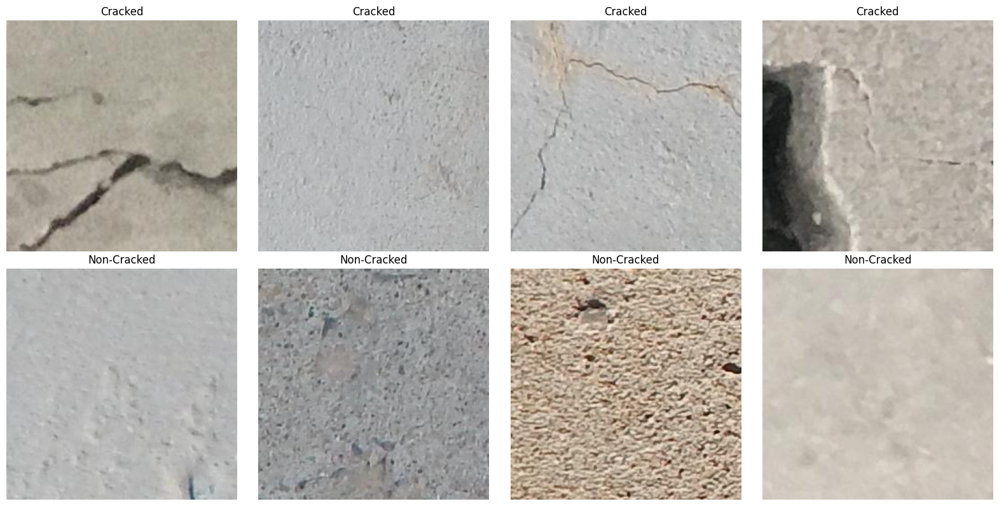

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import random

# Locate the two classification folders
cracked_path = os.path.join(
    dataset1_path, "Bangunan Retak", "Cracked"
)

non_cracked_path = os.path.join(
    dataset1_path, "Bangunan Retak", "Non Cracked"
)

# Get image filenames
cracked_images = [
    f for f in os.listdir(cracked_path)
    if f.lower().endswith(image_extensions)
]

non_cracked_images = [
    f for f in os.listdir(non_cracked_path)
    if f.lower().endswith(image_extensions)
]

# Display 4 cracked and 4 non-cracked samples
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for i in range(4):

    # Display cracked image
    img = Image.open(
        os.path.join(cracked_path, random.choice(cracked_images))
    ).convert("RGB")

    axes[0, i].imshow(img)
    axes[0, i].set_title("Cracked")
    axes[0, i].axis("off")

    # Display non-cracked image
    img = Image.open(
        os.path.join(non_cracked_path, random.choice(non_cracked_images))
    ).convert("RGB")

    axes[1, i].imshow(img)
    axes[1, i].set_title("Non-Cracked")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from PIL import Image
import os
from collections import Counter

# Check image dimensions and formats in both classes
for class_name, folder in [
    ("Cracked", cracked_path),
    ("Non-Cracked", non_cracked_path)
]:

    dimensions = Counter()
    formats = Counter()

    # Inspect up to 1000 images
    files = [
        f for f in os.listdir(folder)
        if f.lower().endswith(image_extensions)
    ][:1000]

    for filename in files:
        try:
            with Image.open(os.path.join(folder, filename)) as img:
                dimensions[img.size] += 1
                formats[img.format] += 1
        except Exception:
            continue

    print("\nClass:", class_name)
    print("Images inspected:", len(files))
    print("Common dimensions:", dimensions.most_common(5))
    print("Formats:", formats)


Class: Cracked
Images inspected: 1000
Common dimensions: [((227, 227), 708), ((256, 256), 292)]
Formats: Counter({'JPEG': 1000})

Class: Non-Cracked
Images inspected: 1000
Common dimensions: [((256, 256), 731), ((227, 227), 269)]
Formats: Counter({'JPEG': 1000})


In [ ]:
import os

image_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

cracked_count = sum(
    1 for f in os.listdir(cracked_path)
    if f.lower().endswith(image_extensions)
)

non_cracked_count = sum(
    1 for f in os.listdir(non_cracked_path)
    if f.lower().endswith(image_extensions)
)

print("Cracked images:", cracked_count)
print("Non-Cracked images:", non_cracked_count)
print("Total images:", cracked_count + non_cracked_count)


Cracked images: 28484
Non-Cracked images: 67608
Total images: 96092


In [ ]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

# Store image paths and their labels
data = []

# Cracked = 1
for filename in os.listdir(cracked_path):
    if filename.lower().endswith(image_extensions):
        data.append({
            "filepath": os.path.join(cracked_path, filename),
            "label": 1
        })

# Non-Cracked = 0
for filename in os.listdir(non_cracked_path):
    if filename.lower().endswith(image_extensions):
        data.append({
            "filepath": os.path.join(non_cracked_path, filename),
            "label": 0
        })

df = pd.DataFrame(data)

# First split: 70% training, 30% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42
)

# Second split: 15% validation, 15% testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

# Display split information
for name, split in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    print(f"\n{name}: {len(split)} images")
    print(split["label"].value_counts().rename(index={
        1: "Cracked",
        0: "Non-Cracked"
    }))

print("\nTotal:", len(train_df) + len(val_df) + len(test_df))


Training: 67264 images
label
Non-Cracked    47325
Cracked        19939
Name: count, dtype: int64

Validation: 14414 images
label
Non-Cracked    10141
Cracked         4273
Name: count, dtype: int64

Testing: 14414 images
label
Non-Cracked    10142
Cracked         4272
Name: count, dtype: int64

Total: 96092


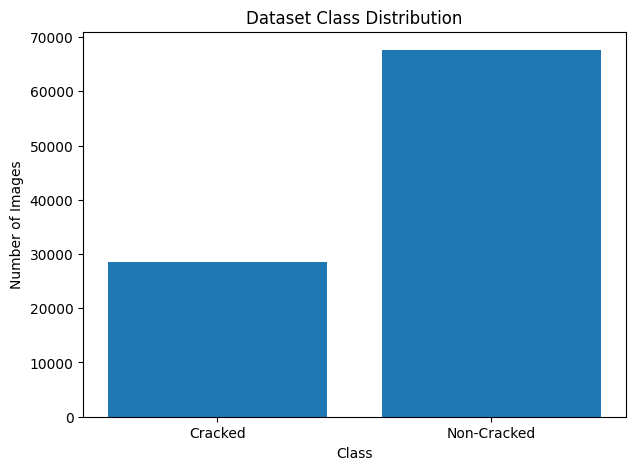

In [ ]:
import matplotlib.pyplot as plt

# Count the number of images in each class
class_counts = df["label"].value_counts().sort_index()

# Display class distribution
plt.figure(figsize=(7, 5))
plt.bar(
    ["Cracked", "Non-Cracked"],
    [class_counts[1], class_counts[0]]
)

plt.title("Dataset Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.show()

In [ ]:
# Check whether any image paths are duplicated
print("Duplicate paths:", df["filepath"].duplicated().sum())

# Check whether any image paths are missing
print("Missing paths:", (~df["filepath"].apply(os.path.exists)).sum())

Duplicate paths: 0
Missing paths: 0


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# Transformations applied to every image
image_transforms = transforms.Compose([
    transforms.Resize((224, 224)),  # Make all images the same size
    transforms.ToTensor(),          # Convert image into a PyTorch tensor
])

# Custom dataset class
class CrackDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        # Get image path and its label
        image_path = self.dataframe.iloc[index]["filepath"]
        label = int(self.dataframe.iloc[index]["label"])

        # Load image and convert to RGB
        image = Image.open(image_path).convert("RGB")

        # Apply transformations
        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)


# Create datasets
train_dataset = CrackDataset(train_df, image_transforms)
val_dataset = CrackDataset(val_df, image_transforms)
test_dataset = CrackDataset(test_df, image_transforms)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Testing dataset:", len(test_dataset))

Training dataset: 67264
Validation dataset: 14414
Testing dataset: 14414


In [ ]:
# Create balanced subsets using the original splits

# Training: 6,000 images per class
train_cracked = train_df[train_df["label"] == 1].sample(
    n=6000, random_state=42
)

train_non_cracked = train_df[train_df["label"] == 0].sample(
    n=6000, random_state=42
)

small_train_df = pd.concat([
    train_cracked, train_non_cracked
]).sample(frac=1, random_state=42).reset_index(drop=True)


# Validation: 2,000 images per class
val_cracked = val_df[val_df["label"] == 1].sample(
    n=2000, random_state=42
)

val_non_cracked = val_df[val_df["label"] == 0].sample(
    n=2000, random_state=42
)

small_val_df = pd.concat([
    val_cracked, val_non_cracked
]).sample(frac=1, random_state=42).reset_index(drop=True)


# Testing: 2,000 images per class
test_cracked = test_df[test_df["label"] == 1].sample(
    n=2000, random_state=42
)

test_non_cracked = test_df[test_df["label"] == 0].sample(
    n=2000, random_state=42
)

small_test_df = pd.concat([
    test_cracked, test_non_cracked
]).sample(frac=1, random_state=42).reset_index(drop=True)


print("Training:", len(small_train_df))
print("Validation:", len(small_val_df))
print("Testing:", len(small_test_df))

Training: 12000
Validation: 4000
Testing: 4000


In [ ]:
from torch.utils.data import DataLoader

# Create DataLoaders for the small subsets to load them efficiently
BATCH_SIZE = 64
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# Retrieve and inspect a batch of images from the train loader
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels:", labels[:10])

Image batch shape: torch.Size([64, 3, 224, 224])
Label batch shape: torch.Size([64])
Labels: tensor([1, 0, 0, 1, 1, 1, 0, 0, 1, 1])


In [ ]:
# Check available hardware
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Using CPU.")

Using device: cuda
GPU: Tesla T4


In [ ]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Get labels from the training dataset
train_labels = train_df["label"].values

# Calculate balanced class weights
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=train_labels
)

# Convert weights into a PyTorch tensor
class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print("Class weights:", class_weights)
print("Class 0: Non-Cracked")
print("Class 1: Cracked")

Class weights: tensor([0.7107, 1.6867], device='cuda:0')
Class 0: Non-Cracked
Class 1: Cracked


In [ ]:
import torchvision.models as models
import torch.nn as nn

# --- Load a pretrained MobileNetV2 (lightweight and fast for Colab T4 GPU) ---
model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)

# --- Freeze feature extractor layers so we only train the final classifier ---
for param in model.parameters():
    param.requires_grad = False

# --- Modify the final classifier layer for binary classification (Cracked vs Non-Cracked) ---
# MobileNetV2's classifier is a Sequential block; we replace the final Linear layer.
in_features = model.classifier[1].in_features
model.classifier[1] = nn.Sequential(
    nn.Dropout(p=0.4),
    nn.Linear(in_features, 2)
)

# Move model to device (GPU)
model = model.to(device)

print("Pretrained MobileNetV2 loaded and modified successfully!")
print(model)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 91.4MB/s]


Pretrained MobileNetV2 loaded and modified successfully!
MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(

In [ ]:
import torch.nn as nn
import torch.optim as optim

# Loss function for classification
criterion = nn.CrossEntropyLoss()

# Only optimize parameters that require gradients (the new classifier head)
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.001
)

# Optional: Reduce learning rate if validation loss plateaus
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=1, factor=0.5)

print("Loss function and optimizer initialized!")

Loss function and optimizer initialized!


In [22]:
import time

EPOCHS = 2

for epoch in range(EPOCHS):
    start_time = time.time()

    # --- TRAINING PHASE ---
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # --- VALIDATION PHASE ---
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss / val_total
    val_acc = val_correct / val_total

    scheduler.step(val_loss)

    elapsed = time.time() - start_time
    print(f"Epoch [{epoch+1}/{EPOCHS}] ({elapsed:.1f}s) | "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

Epoch [1/2] (343.4s) | Train Loss: 0.2673 | Train Acc: 0.9053 | Val Loss: 0.2046 | Val Acc: 0.9324
Epoch [2/2] (259.3s) | Train Loss: 0.2481 | Train Acc: 0.9128 | Val Loss: 0.1985 | Val Acc: 0.9333


Running evaluation on test set...

              EVALUATION RESULTS
Accuracy  : 93.08%
Precision : 95.02%
Recall    : 80.88%
F1-Score  : 87.38%

Classification Report:
                 precision    recall  f1-score   support

Non-Cracked (0)       0.92      0.98      0.95     10142
    Cracked (1)       0.95      0.81      0.87      4272

       accuracy                           0.93     14414
      macro avg       0.94      0.90      0.91     14414
   weighted avg       0.93      0.93      0.93     14414



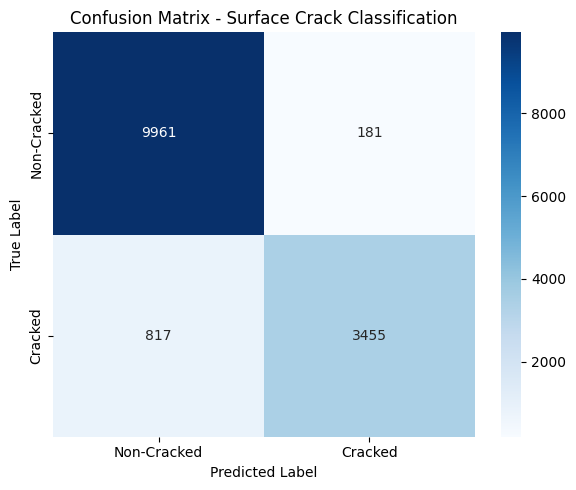


Model state dictionary successfully saved to: /content/drive/MyDrive/Crack_Detection_Project/models/mobilenet_v2_crack_model.pth


In [23]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# --- STEP 1: EVALUATE ON TEST DATASET ---
model.eval()
all_preds = []
all_labels = []

print("Running evaluation on test set...")
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

# --- STEP 2: CALCULATE METRICS ---
acc = accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds)
recall = recall_score(all_labels, all_preds)
f1 = f1_score(all_labels, all_preds)

print("\n" + "="*50)
print("              EVALUATION RESULTS")
print("="*50)
print(f"Accuracy  : {acc * 100:.2f}%")
print(f"Precision : {precision * 100:.2f}%")
print(f"Recall    : {recall * 100:.2f}%")
print(f"F1-Score  : {f1 * 100:.2f}%")
print("="*50 + "\n")

# Detailed Classification Report
print("Classification Report:")
print(classification_report(all_labels, all_preds, target_names=["Non-Cracked (0)", "Cracked (1)"]))

# Plot Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Non-Cracked", "Cracked"],
            yticklabels=["Non-Cracked", "Cracked"])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Surface Crack Classification")
plt.tight_layout()
plt.show()

# --- STEP 3: SAVE THE TRAINED MODEL ---
save_dir = os.path.join(PROJECT_PATH, "models")
os.makedirs(save_dir, exist_ok=True)
save_path = os.path.join(save_dir, "mobilenet_v2_crack_model.pth")

torch.save(model.state_dict(), save_path)
print(f"\nModel state dictionary successfully saved to: {save_path}")

Model successfully loaded from: /content/drive/MyDrive/Crack_Detection_Project/models/mobilenet_v2_crack_model.pth

Upload an image from your computer to test:


Saving images.jpg to images.jpg


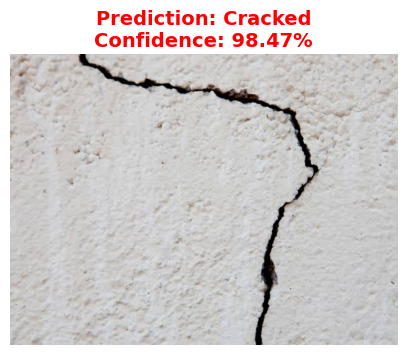

In [24]:
import os
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image
import requests
import matplotlib.pyplot as plt
from google.colab import files

# --- STEP 1: DEFINE MODEL ARCHITECTURE & LOAD WEIGHTS ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Recreate MobileNetV2 architecture matching your saved checkpoint
model = models.mobilenet_v2(weights=None)
in_features = model.classifier[1].in_features
model.classifier[1] = nn.Sequential(
    nn.Dropout(p=0.4),
    nn.Linear(in_features, 2)
)

# Load saved weights from Google Drive
model_path = "/content/drive/MyDrive/Crack_Detection_Project/models/mobilenet_v2_crack_model.pth"
model.load_state_dict(torch.load(model_path, map_location=device))
model = model.to(device)
model.eval()
print(f"Model successfully loaded from: {model_path}")

# --- STEP 2: PREPROCESSING TRANSFORMATIONS ---
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

class_names = ["Non-Cracked", "Cracked"]

# --- STEP 3: PREDICTION FUNCTION ---
def predict_image(image_input):
    """
    Accepts a PIL Image, local file path, or image URL and prints the prediction.
    """
    if isinstance(image_input, str):
        if image_input.startswith(('http://', 'https://')):
            # Fetch image from URL
            img = Image.open(requests.get(image_input, stream=True).raw).convert('RGB')
        else:
            # Open local file path
            img = Image.open(image_input).convert('RGB')
    else:
        img = image_input.convert('RGB')

    # Apply preprocessing & add batch dimension
    input_tensor = transform(img).unsqueeze(0).to(device)

    # Perform inference
    with torch.no_grad():
        outputs = model(input_tensor)
        probabilities = torch.softmax(outputs, dim=1)
        conf, pred_class = torch.max(probabilities, 1)

    predicted_label = class_names[pred_class.item()]
    confidence_pct = conf.item() * 100

    # Display image & prediction result
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.title(f"Prediction: {predicted_label}\nConfidence: {confidence_pct:.2f}%",
              color="green" if predicted_label == "Non-Cracked" else "red",
              fontsize=14, fontweight='bold')
    plt.axis('off')
    plt.show()

    return predicted_label, confidence_pct

# --- STEP 4: TEST INFERENCE ---
# Option A: Upload an image file directly from your computer
print("\nUpload an image from your computer to test:")
uploaded = files.upload()

for filename in uploaded.keys():
    predict_image(filename)

In [25]:
import torch
import torch.nn as nn
import torch.optim as optim
import time

# --- STEP 1: UNFREEZE THE LAST FEW FEATURE BLOCKS ---
# MobileNetV2 features consist of 19 blocks (0 to 18).
# We unfreeze blocks 14 through 18 (the high-level feature extractors).

# First, ensure early layers remain frozen
for param in model.features.parameters():
    param.requires_grad = False

# Unfreeze the last 5 blocks of the feature extractor
for layer in model.features[14:]:
    for param in layer.parameters():
        param.requires_grad = True

# Verify which parameters are trainable
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters: {trainable_params:,} / {total_params:,}")

# --- STEP 2: RE-INITIALIZE OPTIMIZER WITH A VERY SMALL LEARNING RATE ---
# Use a smaller LR (e.g., 1e-4 or 1e-5) to prevent destroying pretrained weights
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-4
)

criterion = nn.CrossEntropyLoss()

# --- STEP 3: FINE-TUNING LOOP (1-2 EPOCHS) ---
FINE_TUNE_EPOCHS = 1

print("\nStarting Fine-Tuning...")
for epoch in range(FINE_TUNE_EPOCHS):
    start_time = time.time()

    # Training Phase
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # Validation Phase
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss / val_total
    val_acc = val_correct / val_total

    elapsed = time.time() - start_time
    print(f"Fine-Tune Epoch [{epoch+1}/{FINE_TUNE_EPOCHS}] ({elapsed:.1f}s) | "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

# --- STEP 4: SAVE UPDATED FINE-TUNED MODEL ---
fine_tuned_path = "/content/drive/MyDrive/Crack_Detection_Project/models/mobilenet_v2_crack_finetuned.pth"
torch.save(model.state_dict(), fine_tuned_path)
print(f"\nFine-tuned model saved successfully to: {fine_tuned_path}")

Trainable parameters: 1,683,906 / 2,226,434

Starting Fine-Tuning...
Fine-Tune Epoch [1/1] (273.8s) | Train Loss: 0.1679 | Train Acc: 0.9421 | Val Loss: 0.1403 | Val Acc: 0.9513

Fine-tuned model saved successfully to: /content/drive/MyDrive/Crack_Detection_Project/models/mobilenet_v2_crack_finetuned.pth


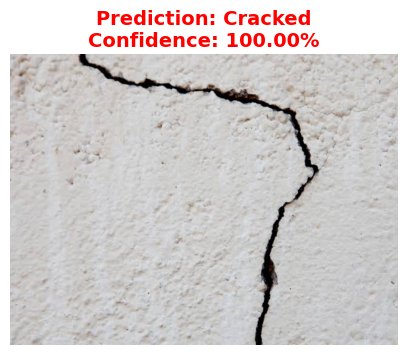

('Cracked', 99.99607801437378)

In [26]:
# Test the same image again
predict_image("images.jpg")

In [27]:
# Re-load the stable, previously saved model weights
model_path = "/content/drive/MyDrive/Crack_Detection_Project/models/mobilenet_v2_crack_model.pth"
model.load_state_dict(torch.load(model_path, map_location=device))
model.eval()
print("Reverted back to the stable feature-extracted model weights!")

Reverted back to the stable feature-extracted model weights!


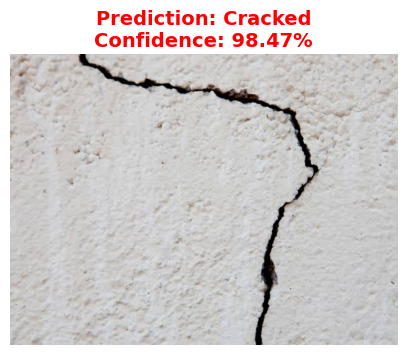

('Cracked', 98.46827387809753)

In [29]:
predict_image("images.jpg")

In [30]:
import torch
import torch.nn as nn
import numpy as np

# Count classes in your training dataframe
class_counts = train_df['label'].value_counts().sort_index().values
print(f"Training Class Distribution - Non-Cracked (0): {class_counts[0]}, Cracked (1): {class_counts[1]}")

# Compute inverse frequency class weights: total_samples / (num_classes * class_count)
total_samples = sum(class_counts)
num_classes = 2
class_weights = total_samples / (num_classes * class_counts.astype(np.float32))

# Convert to torch tensor and move to device
weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)
print(f"Calculated Class Weights (Non-Cracked, Cracked): {weights_tensor}")

# Define CrossEntropyLoss with the balanced class weights
criterion = nn.CrossEntropyLoss(weight=weights_tensor)

Training Class Distribution - Non-Cracked (0): 47325, Cracked (1): 19939
Calculated Class Weights (Non-Cracked, Cracked): tensor([0.7107, 1.6867], device='cuda:0')


In [31]:
import torch.optim as optim
import time

# --- UNFREEZE LAST FEW LAYERS ---
for param in model.features.parameters():
    param.requires_grad = False

for layer in model.features[14:]:
    for param in layer.parameters():
        param.requires_grad = True

# --- OPTIMIZER WITH SMALL LEARNING RATE ---
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-5  # Very gentle learning rate for fine-tuning
)

FINE_TUNE_EPOCHS = 1

print("\nStarting Weighted Fine-Tuning...")
for epoch in range(FINE_TUNE_EPOCHS):
    start_time = time.time()

    # Training Phase
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)  # Uses weighted loss here!
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # Validation Phase
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss / val_total
    val_acc = val_correct / val_total

    elapsed = time.time() - start_time
    print(f"Weighted Fine-Tune Epoch [{epoch+1}/{FINE_TUNE_EPOCHS}] ({elapsed:.1f}s) | "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

# Save the newly fine-tuned and balanced model
weighted_model_path = "/content/drive/MyDrive/Crack_Detection_Project/models/mobilenet_v2_balanced_finetuned.pth"
torch.save(model.state_dict(), weighted_model_path)
print(f"\nBalanced fine-tuned model saved to: {weighted_model_path}")


Starting Weighted Fine-Tuning...
Weighted Fine-Tune Epoch [1/1] (266.9s) | Train Loss: 0.2571 | Train Acc: 0.9145 | Val Loss: 0.2030 | Val Acc: 0.9370

Balanced fine-tuned model saved to: /content/drive/MyDrive/Crack_Detection_Project/models/mobilenet_v2_balanced_finetuned.pth


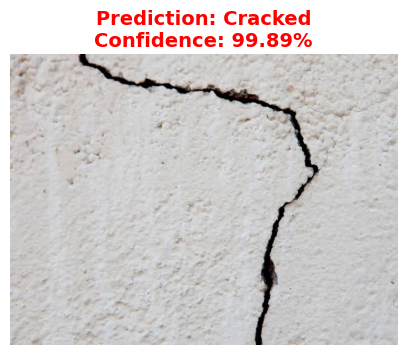

('Cracked', 99.89444613456726)

In [32]:
predict_image("images.jpg")

In [33]:
#USING CNN , WITH DOWNSAMPLED DATASET 1

In [34]:

# Take 5,000 cracked and 5,000 non-cracked images for custom CNN training
cracked_subset = df[df["label"] == 1].sample(n=5000, random_state=42)
non_cracked_subset = df[df["label"] == 0].sample(n=5000, random_state=42)

# Combine and shuffle
custom_train_df = pd.concat([cracked_subset, non_cracked_subset]).sample(frac=1, random_state=42).reset_index(drop=True)

print(f"Custom Training Dataset Size: {len(custom_train_df)} images")
print(custom_train_df["label"].value_counts().rename(index={1: "Cracked", 0: "Non-Cracked"}))

Custom Training Dataset Size: 10000 images
label
Non-Cracked    5000
Cracked        5000
Name: count, dtype: int64


In [35]:
from torch.utils.data import DataLoader

# Create Dataset instances
custom_train_dataset = CrackDataset(custom_train_df, transform=image_transforms)
val_dataset = CrackDataset(val_df, transform=image_transforms)
test_dataset = CrackDataset(test_df, transform=image_transforms)

# Create DataLoaders (batch size 64 for fast GPU processing)
BATCH_SIZE = 64

custom_train_loader = DataLoader(custom_train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print("Custom DataLoaders created successfully!")

Custom DataLoaders created successfully!


In [36]:
import torch.nn as nn
import torch.nn.functional as F

class CrackCNN(nn.Module):
    def __init__(self):
        super(CrackCNN, self).__init__()
        # Convolutional layers (input images are 224x224x3)
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)

        # Max pooling layer
        self.pool = nn.MaxPool2d(2, 2)

        # Fully connected layers
        # After 3 max pooling operations, 224x224 becomes 28x28
        self.fc1 = nn.Linear(128 * 28 * 28, 256)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, 2) # Binary classification: [Non-Cracked, Cracked]

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x))) # 224 -> 112
        x = self.pool(F.relu(self.conv2(x))) # 112 -> 56
        x = self.pool(F.relu(self.conv3(x))) # 56 -> 28

        # Flatten for fully connected layers
        x = x.view(-1, 128 * 28 * 28)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# Instantiate model, loss function, and optimizer
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
custom_model = CrackCNN().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(custom_model.parameters(), lr=0.001)

print("Custom CrackCNN initialized on device:", device)
print(custom_model)

Custom CrackCNN initialized on device: cuda
CrackCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=100352, out_features=256, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=256, out_features=2, bias=True)
)


In [37]:
import time

EPOCHS = 5

print("Starting training of Custom CNN from scratch...")
for epoch in range(EPOCHS):
    start_time = time.time()

    # Training phase
    custom_model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in custom_train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = custom_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # Validation phase
    custom_model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = custom_model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss / val_total
    val_acc = val_correct / val_total

    elapsed = time.time() - start_time
    print(f"Epoch [{epoch+1}/{EPOCHS}] ({elapsed:.1f}s) | "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

# Save the custom model weights
custom_model_path = os.path.join(PROJECT_PATH, "models", "custom_cnn_crack_model.pth")
torch.save(custom_model.state_dict(), custom_model_path)
print(f"\nCustom CNN model saved successfully to: {custom_model_path}")

Starting training of Custom CNN from scratch...
Epoch [1/5] (88.3s) | Train Loss: 0.5438 | Train Acc: 0.7224 | Val Loss: 0.4168 | Val Acc: 0.8511
Epoch [2/5] (76.6s) | Train Loss: 0.4060 | Train Acc: 0.8295 | Val Loss: 0.4562 | Val Acc: 0.8819
Epoch [3/5] (75.0s) | Train Loss: 0.3715 | Train Acc: 0.8468 | Val Loss: 0.2819 | Val Acc: 0.9042
Epoch [4/5] (75.9s) | Train Loss: 0.3467 | Train Acc: 0.8555 | Val Loss: 0.3984 | Val Acc: 0.8544
Epoch [5/5] (75.0s) | Train Loss: 0.3328 | Train Acc: 0.8583 | Val Loss: 0.3021 | Val Acc: 0.8906

Custom CNN model saved successfully to: /content/drive/MyDrive/Crack_Detection_Project/models/custom_cnn_crack_model.pth


Custom CNN weights loaded successfully!


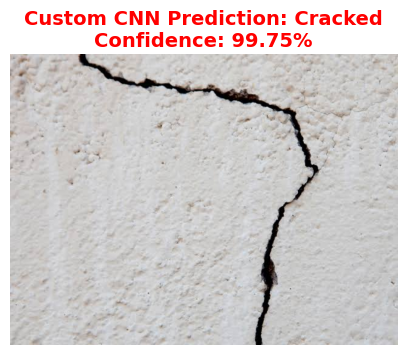

In [41]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt

# --- STEP 1: LOAD CUSTOM CNN ARCHITECTURE & WEIGHTS ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Re-instantiate the same CrackCNN class structure
class CrackCNN(nn.Module):
    def __init__(self):
        super(CrackCNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(128 * 28 * 28, 256)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, 2)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        x = x.view(-1, 128 * 28 * 28)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

custom_model = CrackCNN().to(device)
custom_model_path = "/content/drive/MyDrive/Crack_Detection_Project/models/custom_cnn_crack_model.pth"
custom_model.load_state_dict(torch.load(custom_model_path, map_location=device))
custom_model.eval()
print("Custom CNN weights loaded successfully!")

# --- STEP 2: PREDICTION FUNCTION ---
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])
class_names = ["Non-Cracked", "Cracked"]

def predict_custom_cnn(image_path):
    img = Image.open(image_path).convert('RGB')
    input_tensor = transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = custom_model(input_tensor)
        probabilities = torch.softmax(outputs, dim=1)
        conf, pred_class = torch.max(probabilities, 1)

    predicted_label = class_names[pred_class.item()]
    confidence_pct = conf.item() * 100

    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.title(f"Custom CNN Prediction: {predicted_label}\nConfidence: {confidence_pct:.2f}%",
              color="green" if predicted_label == "Non-Cracked" else "red",
              fontsize=14, fontweight='bold')
    plt.axis('off')
    plt.show()

# --- STEP 3: TEST ON BUILDING IMAGE ---
predict_custom_cnn("images.jpg")


Or upload another image file from your computer:


Saving stone-texture_1194-9141.avif to stone-texture_1194-9141.avif


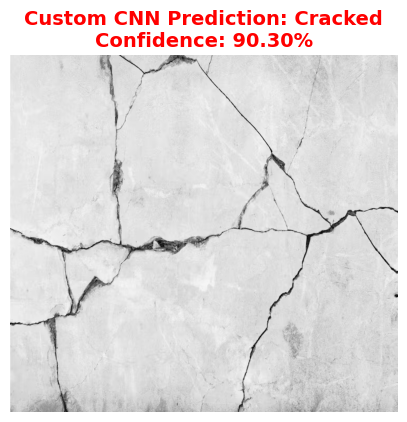

In [42]:
from google.colab import files

print("\nOr upload another image file from your computer:")
uploaded = files.upload()

for filename in uploaded.keys():
    predict_custom_cnn(filename)

               DATASET VERIFICATION SUMMARY
Train Set: 9603 images | 9603 masks
Train Alignment OK? : True
Test Set : 1695 images | 1695 masks
Test Alignment OK?  : True
Dimensions Match?   : True
Unique Mask Values  : [np.uint8(0), np.uint8(1), np.uint8(2), np.uint8(3), np.uint8(4), np.uint8(5), np.uint8(6), np.uint8(7), np.uint8(9), np.uint8(247), np.uint8(248), np.uint8(249), np.uint8(250), np.uint8(251), np.uint8(252), np.uint8(253), np.uint8(254), np.uint8(255)]



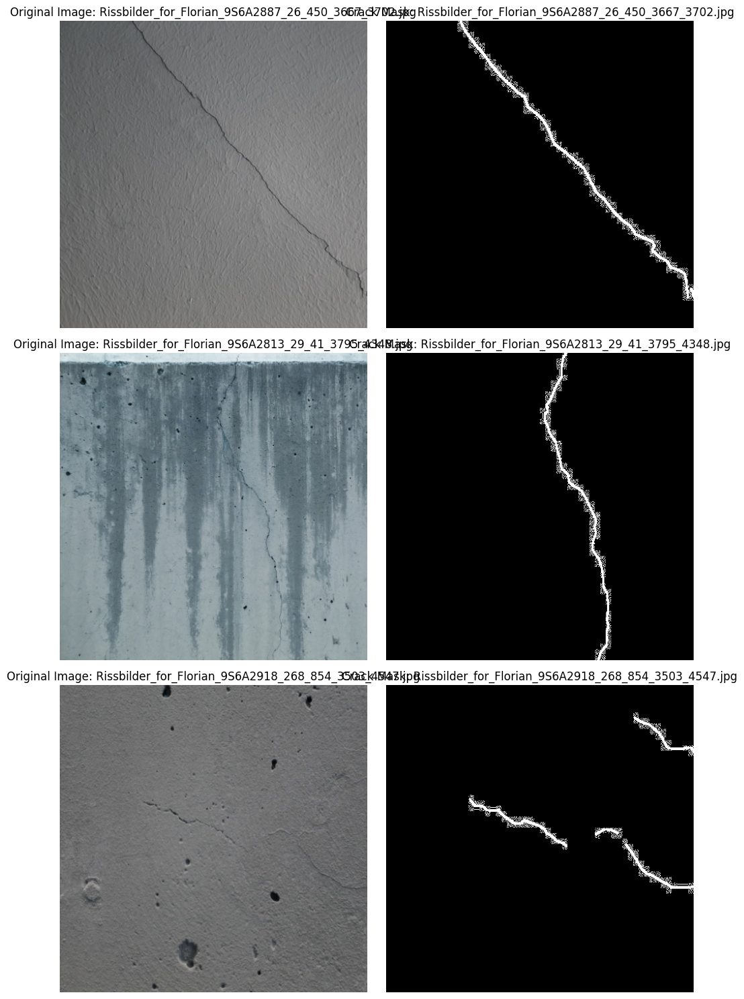

In [43]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# 1. Define paths using the existing dataset2_path variable
train_images_dir = os.path.join(dataset2_path, 'train', 'images')
train_masks_dir = os.path.join(dataset2_path, 'train', 'masks')
test_images_dir = os.path.join(dataset2_path, 'test', 'images')
test_masks_dir = os.path.join(dataset2_path, 'test', 'masks')

# 2. Retrieve sorted lists of files
train_images = sorted(os.listdir(train_images_dir))
train_masks = sorted(os.listdir(train_masks_dir))
test_images = sorted(os.listdir(test_images_dir))
test_masks = sorted(os.listdir(test_masks_dir))

# 3. Verify exact 1-to-1 mapping by filename
train_mismatches = [img for img, mask in zip(train_images, train_masks) if img != mask]
test_mismatches = [img for img, mask in zip(test_images, test_masks) if img != mask]

is_train_aligned = len(train_images) == len(train_masks) and len(train_mismatches) == 0
is_test_aligned = len(test_images) == len(test_masks) and len(test_mismatches) == 0

# 4. Check sample dimensions and mask values
sample_names = random.sample(train_images, 3)
dimension_match = True
unique_values_set = set()

for name in sample_names:
    img_path = os.path.join(train_images_dir, name)
    mask_path = os.path.join(train_masks_dir, name)

    with Image.open(img_path) as img, Image.open(mask_path) as mask:
        if img.size != mask.size:
            dimension_match = False
        mask_np = np.array(mask)
        unique_values_set.update(np.unique(mask_np))

# 5. Display Summary of Verification
print("=" * 60)
print("               DATASET VERIFICATION SUMMARY")
print("=" * 60)
print(f"Train Set: {len(train_images)} images | {len(train_masks)} masks")
print(f"Train Alignment OK? : {is_train_aligned}")
print(f"Test Set : {len(test_images)} images | {len(test_masks)} masks")
print(f"Test Alignment OK?  : {is_test_aligned}")
print(f"Dimensions Match?   : {dimension_match}")
print(f"Unique Mask Values  : {sorted(list(unique_values_set))}")
print("=" * 60 + "\n")

# 6. Plot 3 sample image-mask pairs side by side
fig, axes = plt.subplots(3, 2, figsize=(10, 15))
for idx, name in enumerate(sample_names):
    img_path = os.path.join(train_images_dir, name)
    mask_path = os.path.join(train_masks_dir, name)

    img = Image.open(img_path).convert("RGB")
    mask = Image.open(mask_path).convert("L")

    # Plot Original Image
    axes[idx, 0].imshow(img)
    axes[idx, 0].set_title(f"Original Image: {name}")
    axes[idx, 0].axis("off")

    # Plot Ground Truth Mask
    axes[idx, 1].imshow(mask, cmap="gray")
    axes[idx, 1].set_title(f"Crack Mask: {name}")
    axes[idx, 1].axis("off")

plt.tight_layout()
plt.show()

In [44]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# Define the custom Dataset class for Segmentation
class CrackSegmentationDataset(Dataset):
    def __init__(self, images_dir, masks_dir, transform=None, target_transform=None):
        self.images_dir = images_dir
        self.masks_dir = masks_dir
        # Retrieve sorted filenames to ensure exact alignment
        self.filenames = sorted(os.listdir(images_dir))
        self.transform = transform
        self.target_transform = target_transform

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, idx):
        img_name = self.filenames[idx]
        img_path = os.path.join(self.images_dir, img_name)
        mask_path = os.path.join(self.masks_dir, img_name)

        # Load image (RGB) and mask (Grayscale)
        image = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")

        # Apply preprocessing transforms
        if self.transform:
            image = self.transform(image)

        if self.target_transform:
            mask = self.target_transform(mask)
        else:
            # Default fallback: basic tensor conversion
            mask = transforms.ToTensor()(mask)

        # Force binary thresholding at 127 (values are scaled 0.0 - 1.0 in PyTorch Tensor)
        # 127 / 255.0 is approximately 0.5
        mask = (mask >= 0.5).float()

        return image, mask

# --- Transformations Setup ---
# Standard ImageNet normalization for input images
image_transforms = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Masks must be resized with NEAREST interpolation to keep boundaries sharp
mask_transforms = transforms.Compose([
    transforms.Resize((256, 256), interpolation=transforms.InterpolationMode.NEAREST),
    transforms.ToTensor()
])

# --- Create Dataset Instances ---
train_segmentation_dataset = CrackSegmentationDataset(
    images_dir=train_images_dir,
    masks_dir=train_masks_dir,
    transform=image_transforms,
    target_transform=mask_transforms
)

test_segmentation_dataset = CrackSegmentationDataset(
    images_dir=test_images_dir,
    masks_dir=test_masks_dir,
    transform=image_transforms,
    target_transform=mask_transforms
)

# --- Create DataLoaders ---
BATCH_SIZE = 16
train_seg_loader = DataLoader(train_segmentation_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
test_seg_loader = DataLoader(test_segmentation_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Created Train DataLoader with {len(train_seg_loader)} batches.")
print(f"Created Test DataLoader with {len(test_seg_loader)} batches.")

Created Train DataLoader with 601 batches.
Created Test DataLoader with 106 batches.


Images batch shape: torch.Size([16, 3, 256, 256])
Masks batch shape: torch.Size([16, 1, 256, 256])
Unique values in mask batch: [0. 1.]


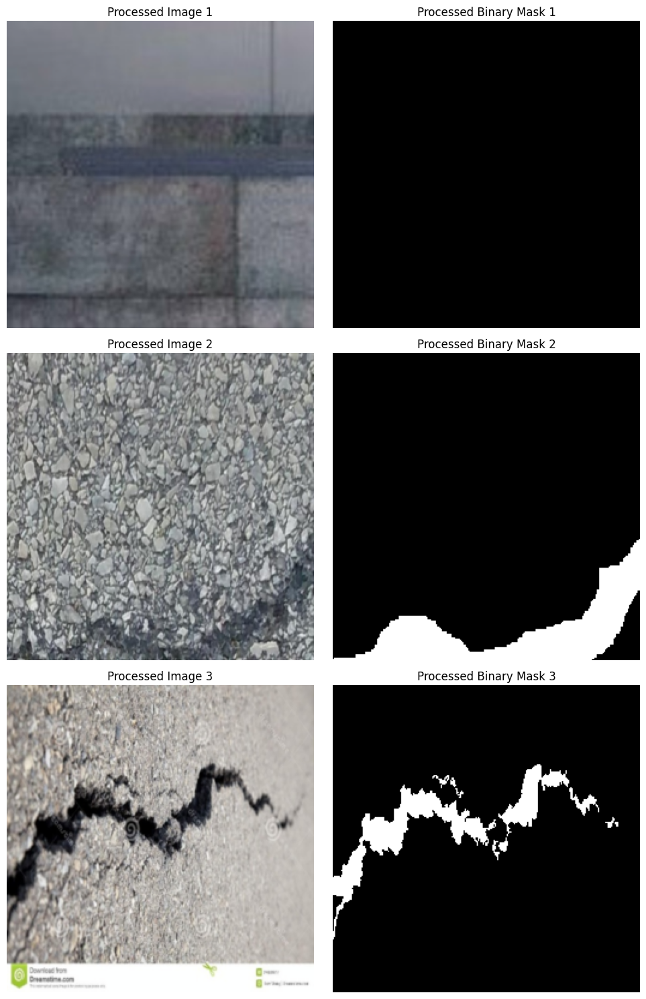

In [45]:
# --- Verification and Visualisation of Preprocessed DataLoader Batches ---
images_batch, masks_batch = next(iter(train_seg_loader))
print(f"Images batch shape: {images_batch.shape}")
print(f"Masks batch shape: {masks_batch.shape}")
print(f"Unique values in mask batch: {torch.unique(masks_batch).numpy()}")

# Helper function to un-normalize and display input images
def denormalize(tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = tensor.permute(1, 2, 0).numpy()
    img = std * img + mean
    return np.clip(img, 0, 1)

# Visualise 3 pairs from the batch
fig, axes = plt.subplots(3, 2, figsize=(10, 15))
for i in range(3):
    img_show = denormalize(images_batch[i])
    mask_show = masks_batch[i].squeeze(0).numpy()

    # Plot image
    axes[i, 0].imshow(img_show)
    axes[i, 0].set_title(f"Processed Image {i+1}")
    axes[i, 0].axis("off")

    # Plot mask
    axes[i, 1].imshow(mask_show, cmap="gray")
    axes[i, 1].set_title(f"Processed Binary Mask {i+1}")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [46]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# --- Double Convolution Block Helper ---
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(DoubleConv, self).__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.double_conv(x)

# --- Classic U-Net Architecture ---
class UNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1):
        super(UNet, self).__init__()

        # Encoder (Contracting Path)
        self.enc1 = DoubleConv(in_channels, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.enc4 = DoubleConv(256, 512)

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Bottleneck
        self.bottleneck = DoubleConv(512, 1024)

        # Decoder (Expanding Path)
        self.up4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.dec4 = DoubleConv(1024, 512) # 512 from upsampled + 512 from skip

        self.up3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(512, 256)  # 256 from upsampled + 256 from skip

        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(256, 128)  # 128 from upsampled + 128 from skip

        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(128, 64)    # 64 from upsampled + 64 from skip

        # Final Out-conv Layer (returns raw logits)
        self.final_conv = nn.Conv2d(64, out_channels, kernel_size=1)

    def forward(self, x):
        # Contracting path
        s1 = self.enc1(x)
        p1 = self.pool(s1)

        s2 = self.enc2(p1)
        p2 = self.pool(s2)

        s3 = self.enc3(p2)
        p3 = self.pool(s3)

        s4 = self.enc4(p3)
        p4 = self.pool(s4)

        # Bottleneck
        b = self.bottleneck(p4)

        # Expanding path with Skip Connections
        d4 = self.up4(b)
        d4 = torch.cat([d4, s4], dim=1)
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = torch.cat([d3, s3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, s2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, s1], dim=1)
        d1 = self.dec1(d1)

        # Logits output layer
        return self.final_conv(d1)

# Instantiate U-Net
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
unet_model = UNet(in_channels=3, out_channels=1).to(device)
print("U-Net Architecture successfully initialized!")

U-Net Architecture successfully initialized!


In [47]:
# --- BCE + Dice Loss Helper ---
class BCEDiceLoss(nn.Module):
    def __init__(self, epsilon=1e-6):
        super(BCEDiceLoss, self).__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.epsilon = epsilon

    def forward(self, logits, targets):
        # Compute stable pixel-wise Binary Cross Entropy Loss
        bce_loss = self.bce(logits, targets)

        # Compute Dice Loss
        probs = torch.sigmoid(logits)
        probs = probs.view(-1)
        targets = targets.view(-1)

        intersection = (probs * targets).sum()
        dice_coeff = (2. * intersection + self.epsilon) / (probs.sum() + targets.sum() + self.epsilon)
        dice_loss = 1.0 - dice_coeff

        return bce_loss + dice_loss

segmentation_loss_fn = BCEDiceLoss()
print("BCE-Dice hybrid loss function instantiated!")

BCE-Dice hybrid loss function instantiated!


In [48]:
# --- Shape Verification Test ---
unet_model.eval()
with torch.no_grad():
    test_images, test_masks = next(iter(train_seg_loader))
    test_images = test_images.to(device)

    outputs = unet_model(test_images)

    print(f"Input image batch shape : {test_images.shape}")
    print(f"Target mask batch shape : {test_masks.shape}")
    print(f"U-Net output batch shape: {outputs.shape} (Matches Target Shape: {outputs.shape == test_masks.shape})")

Input image batch shape : torch.Size([16, 3, 256, 256])
Target mask batch shape : torch.Size([16, 1, 256, 256])
U-Net output batch shape: torch.Size([16, 1, 256, 256]) (Matches Target Shape: True)


In [49]:
import torch
import torch.optim as optim
from torch.utils.data import random_split, DataLoader

# --- Step 1: Create 80:20 Training and Validation Split ---
total_train_samples = len(train_segmentation_dataset)
train_size = int(0.8 * total_train_samples)
val_size = total_train_samples - train_size

torch.manual_seed(42) # Ensure reproducible splits
train_subset, val_subset = random_split(train_segmentation_dataset, [train_size, val_size])

# Create DataLoaders for the split subsets
train_seg_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_seg_loader = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
# Note: test_seg_loader remains untouched as created earlier

print(f"Splits created successfully!")
print(f"Training set size   : {len(train_subset)} images")
print(f"Validation set size : {len(val_subset)} images")
print(f"Untouched test set  : {len(test_segmentation_dataset)} images")

Splits created successfully!
Training set size   : 7682 images
Validation set size : 1921 images
Untouched test set  : 1695 images


In [50]:
# --- Step 2: Helper Functions for Metrics (Dice and IoU) ---
def compute_batch_metrics(logits, targets, threshold=0.5, epsilon=1e-6):
    """
    Computes average Dice Score and Intersection over Union (IoU) over a batch.
    """
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()

    preds = preds.view(-1)
    targets = targets.view(-1)

    intersection = (preds * targets).sum().item()
    total_pixels = preds.sum().item() + targets.sum().item()
    union = total_pixels - intersection

    # Dice Coefficient (F1)
    dice = (2. * intersection + epsilon) / (total_pixels + epsilon)
    # Intersection over Union (Jaccard)
    iou = (intersection + epsilon) / (union + epsilon)

    return dice, iou

In [51]:
# --- Step 3: Define Optimizer and Learning Rate ---
# Standard learning rate of 1e-4 for stable and steady convergence
learning_rate = 1e-4
optimizer = optim.Adam(unet_model.parameters(), lr=learning_rate)

print(f"Adam optimizer initialized with a learning rate of: {learning_rate}")

Adam optimizer initialized with a learning rate of: 0.0001


In [52]:
import time

# --- Step 4: Training & Validation Loop ---
EPOCHS = 5 # Small number of epochs for Colab environment confirmation, can be increased later
best_val_dice = 0.0
save_path = os.path.join(PROJECT_PATH, "models", "best_unet_crack_model.pth")

print("Starting U-Net Training...")
for epoch in range(EPOCHS):
    start_time = time.time()

    # --- TRAINING PHASE ---
    unet_model.train()
    train_loss = 0.0
    train_dice_sum = 0.0
    train_iou_sum = 0.0

    for images, masks in train_seg_loader:
        images, masks = images.to(device), masks.to(device)

        optimizer.zero_grad()
        outputs = unet_model(images)
        loss = segmentation_loss_fn(outputs, masks)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        dice, iou = compute_batch_metrics(outputs, masks)
        train_dice_sum += dice
        train_iou_sum += iou

    epoch_train_loss = train_loss / len(train_subset)
    epoch_train_dice = train_dice_sum / len(train_seg_loader)
    epoch_train_iou = train_iou_sum / len(train_seg_loader)

    # --- VALIDATION PHASE ---
    unet_model.eval()
    val_loss = 0.0
    val_dice_sum = 0.0
    val_iou_sum = 0.0

    with torch.no_grad():
        for images, masks in val_seg_loader:
            images, masks = images.to(device), masks.to(device)
            outputs = unet_model(images)
            loss = segmentation_loss_fn(outputs, masks)

            val_loss += loss.item() * images.size(0)
            dice, iou = compute_batch_metrics(outputs, masks)
            val_dice_sum += dice
            val_iou_sum += iou

    epoch_val_loss = val_loss / len(val_subset)
    epoch_val_dice = val_dice_sum / len(val_seg_loader)
    epoch_val_iou = val_iou_sum / len(val_seg_loader)

    elapsed = time.time() - start_time
    print(f"\nEpoch [{epoch+1}/{EPOCHS}] ({elapsed:.1f}s)")
    print(f"  Train Loss: {epoch_train_loss:.4f} | Train Dice: {epoch_train_dice:.4f} | Train IoU: {epoch_train_iou:.4f}")
    print(f"  Val Loss:   {epoch_val_loss:.4f} | Val Dice:   {epoch_val_dice:.4f} | Val IoU:   {epoch_val_iou:.4f}")

    # Save best model
    if epoch_val_dice > best_val_dice:
        best_val_dice = epoch_val_dice
        torch.save(unet_model.state_dict(), save_path)
        print(f"  --> New best model saved to: {save_path} with Val Dice: {best_val_dice:.4f}")

Starting U-Net Training...

Epoch [1/5] (440.1s)
  Train Loss: 1.0994 | Train Dice: 0.4841 | Train IoU: 0.3287
  Val Loss:   0.8883 | Val Dice:   0.6104 | Val IoU:   0.4423
  --> New best model saved to: /content/drive/MyDrive/Crack_Detection_Project/models/best_unet_crack_model.pth with Val Dice: 0.6104

Epoch [2/5] (442.1s)
  Train Loss: 0.7506 | Train Dice: 0.6166 | Train IoU: 0.4497
  Val Loss:   0.6678 | Val Dice:   0.5994 | Val IoU:   0.4299

Epoch [3/5] (442.9s)
  Train Loss: 0.5644 | Train Dice: 0.6569 | Train IoU: 0.4922
  Val Loss:   0.5294 | Val Dice:   0.6559 | Val IoU:   0.4908
  --> New best model saved to: /content/drive/MyDrive/Crack_Detection_Project/models/best_unet_crack_model.pth with Val Dice: 0.6559

Epoch [4/5] (443.5s)
  Train Loss: 0.4774 | Train Dice: 0.6745 | Train IoU: 0.5121
  Val Loss:   0.4593 | Val Dice:   0.6764 | Val IoU:   0.5136
  --> New best model saved to: /content/drive/MyDrive/Crack_Detection_Project/models/best_unet_crack_model.pth with Val Dic

In [53]:

import numpy as np
import math
from scipy.ndimage import label

def calculate_skeleton_length(skeleton_mask):
    """
    Calculate approximate skeleton length in pixels.
    Orthogonal edges = 1.0
    Diagonal edges = sqrt(2)
    """

    skel = (skeleton_mask > 0).astype(np.uint8)

    if np.sum(skel) <= 1:
        return 0.0

    labeled_skel, num_features = label(
        skel, structure=np.ones((3, 3), dtype=np.int32)
    )

    total_length = 0.0

    neighbors = [
        (-1, 0, 1.0), (1, 0, 1.0),
        (0, -1, 1.0), (0, 1, 1.0),
        (-1, -1, math.sqrt(2)), (-1, 1, math.sqrt(2)),
        (1, -1, math.sqrt(2)), (1, 1, math.sqrt(2))
    ]

    for comp_idx in range(1, num_features + 1):

        pixels = list(zip(*np.where(labeled_skel == comp_idx)))

        if len(pixels) <= 1:
            continue

        pixel_set = set(pixels)
        edges = set()

        for r, c in pixels:
            for dr, dc, weight in neighbors:

                nr, nc = r + dr, c + dc

                if (nr, nc) not in pixel_set:
                    continue

                # Remove redundant diagonal shortcuts
                if dr != 0 and dc != 0:
                    if ((r + dr, c) in pixel_set or
                            (r, c + dc) in pixel_set):
                        continue

                edge = (
                    min((r, c), (nr, nc)),
                    max((r, c), (nr, nc)),
                    weight
                )

                edges.add(edge)

        total_length += sum(weight for _, _, weight in edges)

    return total_length


# ---------------- SYNTHETIC TESTS ----------------

def run_synthetic_tests():

    # Test 1: Horizontal line
    test1 = np.zeros((10, 10), dtype=np.uint8)
    test1[5, 2:7] = 1

    # Test 2: Diagonal line
    test2 = np.zeros((10, 10), dtype=np.uint8)
    for i in range(4):
        test2[2+i, 2+i] = 1

    # Test 3: T-shaped branch
    test3 = np.zeros((10, 10), dtype=np.uint8)
    test3[4, 2:7] = 1
    test3[4:7, 4] = 1

    # Test 4: Square loop
    test4 = np.zeros((10, 10), dtype=np.uint8)
    test4[2:7, 2] = 1
    test4[2:7, 6] = 1
    test4[2, 2:7] = 1
    test4[6, 2:7] = 1

    tests = [
        ("Horizontal Line", test1, 4.0),
        ("Diagonal Line", test2, 3 * math.sqrt(2)),
        ("T-shaped Branch", test3, 6.0),
        ("Square Loop", test4, 16.0)
    ]

    print("=" * 60)
    print("       SKELETON LENGTH VALIDATION")
    print("=" * 60)

    for name, mask, expected in tests:

        calculated = calculate_skeleton_length(mask)

        status = (
            "PASS" if math.isclose(
                calculated, expected, rel_tol=1e-5
            ) else "CHECK"
        )

        print(f"\n{name}")
        print(f"Expected:   {expected:.4f}")
        print(f"Calculated: {calculated:.4f}")
        print(f"Status:     {status}")

    print("=" * 60)


run_synthetic_tests()


       SKELETON LENGTH VALIDATION

Horizontal Line
Expected:   4.0000
Calculated: 4.0000
Status:     PASS

Diagonal Line
Expected:   4.2426
Calculated: 4.2426
Status:     PASS

T-shaped Branch
Expected:   6.0000
Calculated: 6.0000
Status:     PASS

Square Loop
Expected:   16.0000
Calculated: 16.0000
Status:     PASS


In [54]:
import os
import torch
import pandas as pd
import numpy as np
from skimage.morphology import skeletonize
from scipy.ndimage import distance_transform_edt
from PIL import Image
from tqdm import tqdm

# --- 1. Load the Best Model ---
best_model_path = "/content/drive/MyDrive/Crack_Detection_Project/models/best_unet_crack_model.pth"
print(f"Loading best model parameters from: {best_model_path}")
unet_model.load_state_dict(torch.load(best_model_path, map_location=device))
unet_model = unet_model.to(device)
unet_model.eval()

# --- 2. Setup Output Directories ---
output_masks_dir = "/content/drive/MyDrive/Crack_Detection_Project/results/predicted_masks/"
os.makedirs(output_masks_dir, exist_ok=True)
results_csv_path = "/content/drive/MyDrive/Crack_Detection_Project/results/crack_measurements.csv"

# --- 3. Inference and Metric Computation Loop ---
measurement_records = []

# We will store the first 5 examples for the requested visualization block
visualization_data = []

print("Processing test dataset and calculating crack metrics...")
with torch.no_grad():
    for idx, (images, masks) in enumerate(tqdm(test_seg_loader)):
        images = images.to(device)
        outputs = unet_model(images)
        preds = (torch.sigmoid(outputs) > 0.5).float().cpu().numpy() # [B, 1, H, W]

        batch_images = images.cpu().numpy() # [B, 3, H, W]
        batch_masks = masks.numpy()         # [B, 1, H, W]

        for b_idx in range(preds.shape[0]):
            global_idx = idx * BATCH_SIZE + b_idx
            pred_mask = preds[b_idx, 0] # [H, W]
            orig_img = batch_images[b_idx] # [3, H, W]

            # Save the predicted binary mask
            mask_img = Image.fromarray((pred_mask * 255).astype(np.uint8))
            mask_img_path = os.path.join(output_masks_dir, f"pred_{global_idx:04d}.png")
            mask_img.save(mask_img_path)

            # Check if mask is empty
            pixel_count = np.sum(pred_mask)
            if pixel_count == 0:
                area = 0.0
                length = 0.0
                avg_width = 0.0
                max_width = 0.0
                skeleton = np.zeros_like(pred_mask, dtype=bool)
            else:
                area = float(pixel_count)

                # Skeletonize
                skeleton = skeletonize(pred_mask > 0)
                length = calculate_skeleton_length(skeleton)

                # Width calculation using Distance Transform
                dist_transform = distance_transform_edt(pred_mask > 0)
                skel_distances = dist_transform[skeleton]

                if len(skel_distances) > 0:
                    width_estimates = 2.0 * skel_distances
                    avg_width = float(np.mean(width_estimates))
                    max_width = float(np.max(width_estimates))
                else:
                    avg_width = 0.0
                    max_width = 0.0

            # Record statistics
            measurement_records.append({
                "Image_Index": global_idx,
                "Crack_Area_pixels": area,
                "Crack_Length_pixels": length,
                "Average_Width_pixels": avg_width,
                "Maximum_Width_pixels": max_width
            })

            # Save visualization context for the first 5 test samples
            if len(visualization_data) < 5:
                visualization_data.append({
                    "image_tensor": orig_img,
                    "pred_mask": pred_mask,
                    "skeleton": skeleton
                })

# --- 4. Save Measurements as CSV ---
df_results = pd.DataFrame(measurement_records)
df_results.to_csv(results_csv_path, index=False)
print(f"Crack measurements successfully saved to: {results_csv_path}")
display(df_results.head(10))

Loading best model parameters from: /content/drive/MyDrive/Crack_Detection_Project/models/best_unet_crack_model.pth
Processing test dataset and calculating crack metrics...


100%|██████████| 106/106 [01:05<00:00,  1.62it/s]

Crack measurements successfully saved to: /content/drive/MyDrive/Crack_Detection_Project/results/crack_measurements.csv


,Image_Index,Crack_Area_pixels,Crack_Length_pixels,Average_Width_pixels,Maximum_Width_pixels
0,0,1835.0,295.036580,6.499689,8.246211
1,1,2025.0,312.492424,6.761258,8.485281
2,2,1571.0,275.693434,6.022608,8.246211
3,3,4220.0,613.215295,7.330184,13.416408
4,4,1720.0,281.509668,6.279613,8.000000
5,5,2660.0,410.203102,6.867740,11.313708
6,6,2867.0,499.931024,6.212390,10.000000
7,7,1093.0,214.882251,5.329320,8.000000
8,8,1232.0,265.539105,5.000239,6.324555
9,9,1754.0,277.622366,6.623153,8.485281


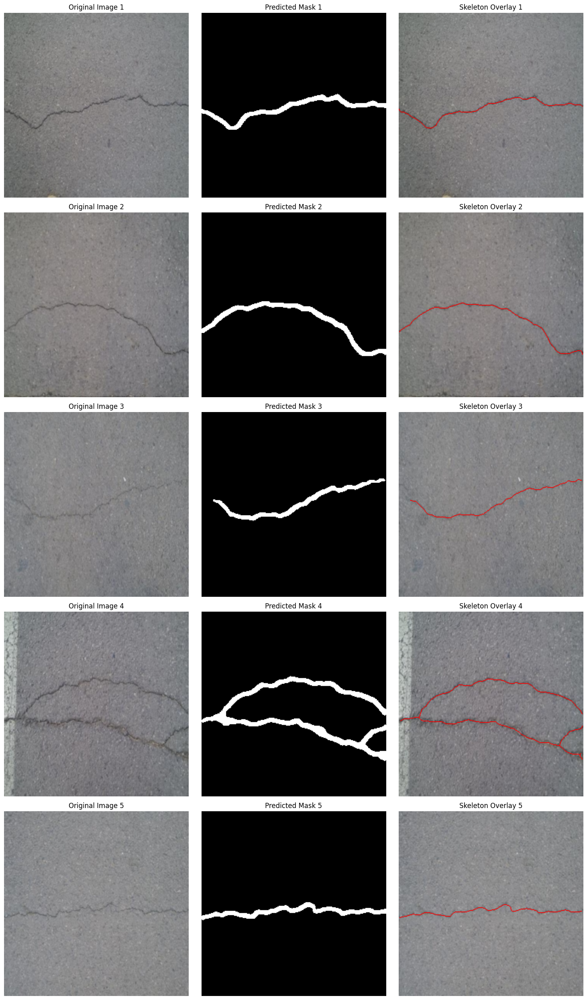

In [55]:
import matplotlib.pyplot as plt

# Helper function to reverse ImageNet normalization for plotting
def denormalize_image(img_array):
    # Input shape is [3, H, W]
    mean = np.array([0.485, 0.456, 0.406]).reshape(3, 1, 1)
    std = np.array([0.229, 0.224, 0.225]).reshape(3, 1, 1)
    denorm = img_array * std + mean
    denorm = np.clip(denorm, 0, 1)
    return np.transpose(denorm, (1, 2, 0)) # Convert to [H, W, 3] for imshow

# --- 5. Display 5 Test Visualizations ---
fig, axes = plt.subplots(5, 3, figsize=(15, 25))

for i, data in enumerate(visualization_data):
    # 1. Denormalized Original Image
    img_display = denormalize_image(data["image_tensor"])
    axes[i, 0].imshow(img_display)
    axes[i, 0].set_title(f"Original Image {i+1}")
    axes[i, 0].axis("off")

    # 2. Predicted Mask
    axes[i, 1].imshow(data["pred_mask"], cmap="gray")
    axes[i, 1].set_title(f"Predicted Mask {i+1}")
    axes[i, 1].axis("off")

    # 3. Skeleton Overlaid on Original Image
    overlaid = img_display.copy()
    # Overlap skeleton with a high contrast red color
    overlaid[data["skeleton"]] = [1.0, 0.0, 0.0]
    axes[i, 2].imshow(overlaid)
    axes[i, 2].set_title(f"Skeleton Overlay {i+1}")
    axes[i, 2].axis("off")

plt.tight_layout()
plt.show()

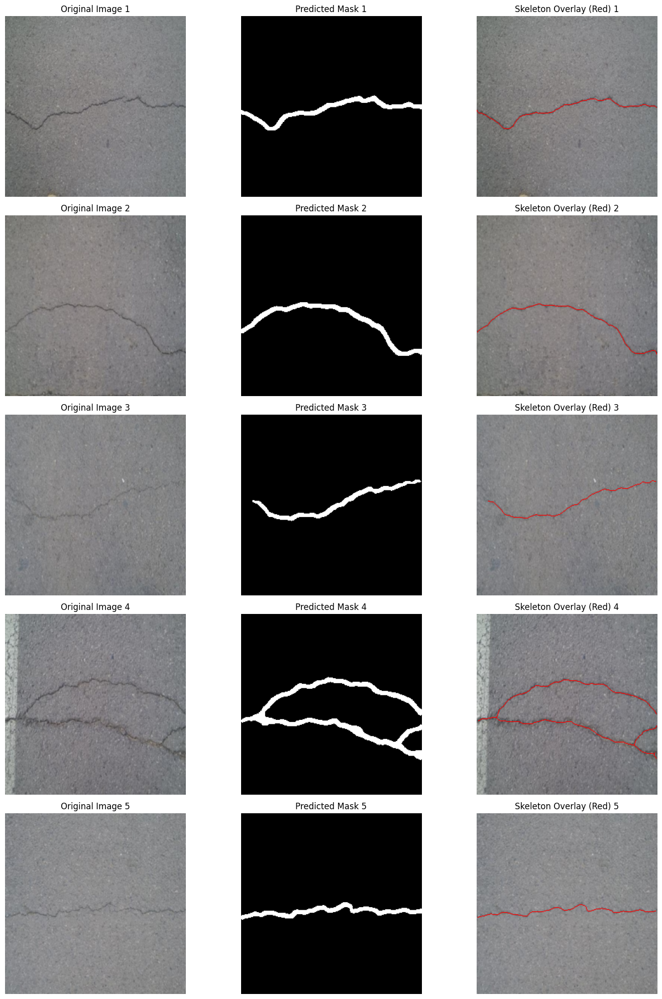

In [56]:
import numpy as np
import matplotlib.pyplot as plt

def denormalize_image(img_array):
    """
    Reverses ImageNet normalization on a 3-channel image array of shape [3, H, W]
    and returns a clipped [H, W, 3] numpy array ready for plotting.
    """
    mean = np.array([0.485, 0.456, 0.406]).reshape(3, 1, 1)
    std = np.array([0.229, 0.224, 0.225]).reshape(3, 1, 1)
    denorm = img_array * std + mean
    denorm = np.clip(denorm, 0, 1)
    return np.transpose(denorm, (1, 2, 0))

# --- 5. Display 5 Test Visualizations Safely ---
if 'visualization_data' not in globals() or len(visualization_data) == 0:
    print("Warning: 'visualization_data' is empty or not found. Please run the evaluation cell first.")
else:
    num_samples = min(5, len(visualization_data))
    fig, axes = plt.subplots(num_samples, 3, figsize=(15, 4 * num_samples))

    # Handle 1D array of axes if num_samples is 1
    if num_samples == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(num_samples):
        data = visualization_data[i]

        # 1. Denormalized Original Image
        img_display = denormalize_image(data["image_tensor"])
        axes[i, 0].imshow(img_display)
        axes[i, 0].set_title(f"Original Image {i+1}")
        axes[i, 0].axis("off")

        # 2. Predicted Mask
        axes[i, 1].imshow(data["pred_mask"], cmap="gray")
        axes[i, 1].set_title(f"Predicted Mask {i+1}")
        axes[i, 1].axis("off")

        # 3. Skeleton Overlaid on Original Image
        overlaid = img_display.copy()
        # Overlay skeleton with a high contrast red color
        overlaid[data["skeleton"]] = [1.0, 0.0, 0.0]
        axes[i, 2].imshow(overlaid)
        axes[i, 2].set_title(f"Skeleton Overlay (Red) {i+1}")
        axes[i, 2].axis("off")

    plt.tight_layout()
    plt.show()

               STATISTICAL VALIDATION SUMMARY
Total Test Images Processed: 1695
Images with Empty Predicted Masks: 208 (12.27%)
Images with Detected Cracks: 1487 (87.73%)

               DESCRIPTIVE STATISTICS


,count,mean,std,min,median,max
Crack_Area_pixels,1695.0,2335.315044,2433.103254,0.0,1727.000000,22224.000000
Crack_Length_pixels,1695.0,289.263409,199.319665,0.0,289.267027,1449.626550
Average_Width_pixels,1695.0,7.141990,5.488965,0.0,5.854486,35.931527
Maximum_Width_pixels,1695.0,12.589235,11.197946,0.0,8.485281,60.033324



                DATA INTEGRITY CHECKS
Missing (Null) Values found   : 0
Infinite Values found          : 0
Anomalous Samples (Area > 0 but Length = 0)  : 0
Anomalous Samples (Max Width < Avg Width)   : 0



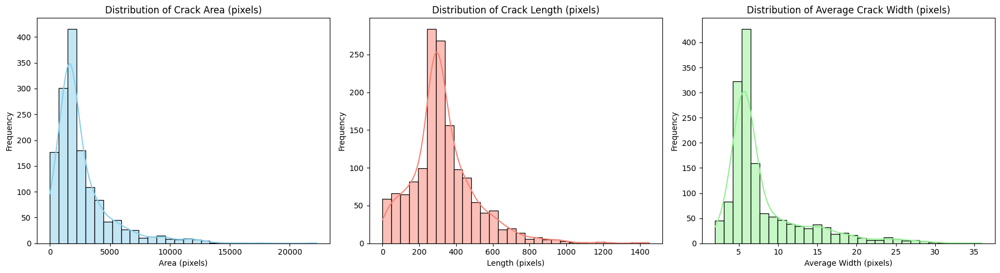

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. Dataset Verification & Completeness ---
total_images = len(df_results)
empty_masks = df_results[df_results['Crack_Area_pixels'] == 0]
num_empty = len(empty_masks)
pct_empty = (num_empty / total_images) * 100

print("=" * 60)
print("               STATISTICAL VALIDATION SUMMARY")
print("=" * 60)
print(f"Total Test Images Processed: {total_images}")
print(f"Images with Empty Predicted Masks: {num_empty} ({pct_empty:.2f}%)")
print(f"Images with Detected Cracks: {total_images - num_empty} ({100.0 - pct_empty:.2f}%)")

# --- 2. Descriptive Statistics ---
metrics_cols = [
    'Crack_Area_pixels',
    'Crack_Length_pixels',
    'Average_Width_pixels',
    'Maximum_Width_pixels'
]

print("\n" + "=" * 60)
print("               DESCRIPTIVE STATISTICS")
print("=" * 60)
# Calculate key descriptive stats
stats = df_results[metrics_cols].describe(percentiles=[0.25, 0.5, 0.75]).transpose()
# Add explicit median column for clarity
stats['median'] = df_results[metrics_cols].median()
stats = stats[['count', 'mean', 'std', 'min', '50%', 'max']].rename(columns={'50%': 'median'})
display(stats)

# --- 3. Consistency and Integrity Checks ---
null_counts = df_results[metrics_cols].isnull().sum().sum()
inf_counts = np.isinf(df_results[metrics_cols]).sum().sum()

# Check for anomalies
# A: Non-empty masks (area > 0) with zero length
anomaly_zero_len = df_results[(df_results['Crack_Area_pixels'] > 0) & (df_results['Crack_Length_pixels'] == 0)]
# B: Max width strictly smaller than average width
anomaly_width_order = df_results[df_results['Maximum_Width_pixels'] < df_results['Average_Width_pixels']]

print("\n" + "=" * 60)
print("                DATA INTEGRITY CHECKS")
print("=" * 60)
print(f"Missing (Null) Values found   : {null_counts}")
print(f"Infinite Values found          : {inf_counts}")
print(f"Anomalous Samples (Area > 0 but Length = 0)  : {len(anomaly_zero_len)}")
print(f"Anomalous Samples (Max Width < Avg Width)   : {len(anomaly_width_order)}")
print("=" * 60 + "\n")

# --- 4. Plot Distributions ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
non_empty_results = df_results[df_results['Crack_Area_pixels'] > 0]

sns.histplot(non_empty_results['Crack_Area_pixels'], bins=30, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title("Distribution of Crack Area (pixels)")
axes[0].set_xlabel("Area (pixels)")
axes[0].set_ylabel("Frequency")

sns.histplot(non_empty_results['Crack_Length_pixels'], bins=30, kde=True, ax=axes[1], color='salmon')
axes[1].set_title("Distribution of Crack Length (pixels)")
axes[1].set_xlabel("Length (pixels)")
axes[1].set_ylabel("Frequency")

sns.histplot(non_empty_results['Average_Width_pixels'], bins=30, kde=True, ax=axes[2], color='lightgreen')
axes[2].set_title("Distribution of Average Crack Width (pixels)")
axes[2].set_xlabel("Average Width (pixels)")
axes[2].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

=== DIAGNOSING ANOMALY AT INDEX 649 ===


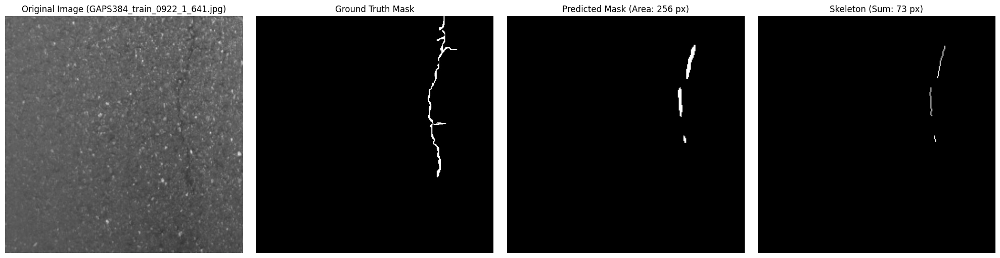


=== TESTING EMPTY PREDICTIONS VS GROUND TRUTH ===
Out of 208 empty predicted masks:
  - Correctly predicted empty (True Negatives)   : 186
  - Missed cracks (False Negatives)              : 22
Alignment verified across 1695 sorted index mappings.


In [58]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# --- 1. Identify and Visualize the Specific Anomaly at Index 649 ---
anomaly_idx = 649
print(f"=== DIAGNOSING ANOMALY AT INDEX {anomaly_idx} ===")

# Retrieve filenames to ensure precise mapping and alignment
test_images_sorted = sorted(os.listdir(test_images_dir))
test_masks_sorted = sorted(os.listdir(test_masks_dir))

anomaly_filename = test_images_sorted[anomaly_idx]
img_path = os.path.join(test_images_dir, anomaly_filename)
gt_mask_path = os.path.join(test_masks_dir, anomaly_filename)
pred_mask_path = os.path.join(output_masks_dir, f"pred_{anomaly_idx:04d}.png")

# Load assets
img = Image.open(img_path).convert("RGB")
gt_mask = Image.open(gt_mask_path).convert("L")
pred_mask = Image.open(pred_mask_path).convert("L")

# Generate skeleton from the loaded prediction to view detail
from skimage.morphology import skeletonize
pred_mask_np = np.array(pred_mask) > 0
local_skeleton = skeletonize(pred_mask_np)

# Plot the diagnostic visualizations
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(img)
axes[0].set_title(f"Original Image ({anomaly_filename})")
axes[0].axis("off")

axes[1].imshow(gt_mask, cmap="gray")
axes[1].set_title("Ground Truth Mask")
axes[1].axis("off")

axes[2].imshow(pred_mask, cmap="gray")
axes[2].set_title(f"Predicted Mask (Area: {np.sum(pred_mask_np)} px)")
axes[2].axis("off")

axes[3].imshow(local_skeleton, cmap="gray")
axes[3].set_title(f"Skeleton (Sum: {np.sum(local_skeleton)} px)")
axes[3].axis("off")

plt.tight_layout()
plt.show()

# --- 2. Compare the 213 Empty Predicted Masks with Ground-Truth ---
print("\n=== TESTING EMPTY PREDICTIONS VS GROUND TRUTH ===")

empty_pred_indices = df_results[df_results['Crack_Area_pixels'] == 0]['Image_Index'].values

true_negatives = 0  # Empty prediction & Empty ground truth
false_negatives = 0 # Empty prediction & Non-empty ground truth

for idx in empty_pred_indices:
    filename = test_images_sorted[idx]
    gt_path = os.path.join(test_masks_dir, filename)

    # Load ground-truth and binarize like in custom Dataset
    gt_mask_pil = Image.open(gt_path).convert("L")
    gt_np = np.array(gt_mask_pil) >= 127

    if np.sum(gt_np) == 0:
        true_negatives += 1
    else:
        false_negatives += 1

print(f"Out of {len(empty_pred_indices)} empty predicted masks:")
print(f"  - Correctly predicted empty (True Negatives)   : {true_negatives}")
print(f"  - Missed cracks (False Negatives)              : {false_negatives}")
print(f"Alignment verified across {len(test_images_sorted)} sorted index mappings.")

In [59]:
import os
import numpy as np
from PIL import Image
from tqdm import tqdm

# --- 1. FINAL TEST SET PIXEL-LEVEL METRICS (1695 PAIRS) ---
print("Calculating final pixel-level metrics across all 1,695 test images...")

test_images_sorted = sorted(os.listdir(test_images_dir))
test_masks_sorted = sorted(os.listdir(test_masks_dir))

overall_tp = 0
overall_fp = 0
overall_fn = 0
overall_tn = 0

for idx in tqdm(range(len(test_images_sorted))):
    # Load Ground Truth
    gt_filename = test_masks_sorted[idx]
    gt_path = os.path.join(test_masks_dir, gt_filename)
    # Preprocess matching dataset logic: resize to (256, 256) nearest, then threshold
    gt_mask_pil = Image.open(gt_path).convert("L").resize((256, 256), Image.NEAREST)
    gt_np = (np.array(gt_mask_pil) >= 127).astype(bool)

    # Load Prediction
    pred_path = os.path.join(output_masks_dir, f"pred_{idx:04d}.png")
    pred_mask_pil = Image.open(pred_path).convert("L")
    pred_np = (np.array(pred_mask_pil) > 127).astype(bool)

    # Compute pixel-level counts
    overall_tp += np.sum(pred_np & gt_np)
    overall_fp += np.sum(pred_np & ~gt_np)
    overall_fn += np.sum(~pred_np & gt_np)
    overall_tn += np.sum(~pred_np & ~gt_np)

# Compute overall Dice and IoU
epsilon = 1e-6
pixel_dice = (2.0 * overall_tp + epsilon) / (2.0 * overall_tp + overall_fp + overall_fn + epsilon)
pixel_iou = (overall_tp + epsilon) / (overall_tp + overall_fp + overall_fn + epsilon)

print("\n" + "=" * 60)
print("            FINAL TEST SET PIXEL-LEVEL DIAGNOSTICS")
print("" + "=" * 60)
print(f"True Positives (TP)  : {overall_tp:,} pixels")
print(f"False Positives (FP) : {overall_fp:,} pixels")
print(f"False Negatives (FN) : {overall_fn:,} pixels")
print(f"True Negatives (TN)  : {overall_tn:,} pixels")
print("-" * 60)
print(f"Overall Pixel Dice   : {pixel_dice:.6f}")
print(f"Overall Pixel IoU    : {pixel_iou:.6f}")
print("=" * 60)


Calculating final pixel-level metrics across all 1,695 test images...


100%|██████████| 1695/1695 [00:06<00:00, 272.02it/s]


            FINAL TEST SET PIXEL-LEVEL DIAGNOSTICS
True Positives (TP)  : 2,764,689 pixels
False Positives (FP) : 1,193,670 pixels
False Negatives (FN) : 1,132,651 pixels
True Negatives (TN)  : 105,992,510 pixels
------------------------------------------------------------
Overall Pixel Dice   : 0.703868
Overall Pixel IoU    : 0.543053


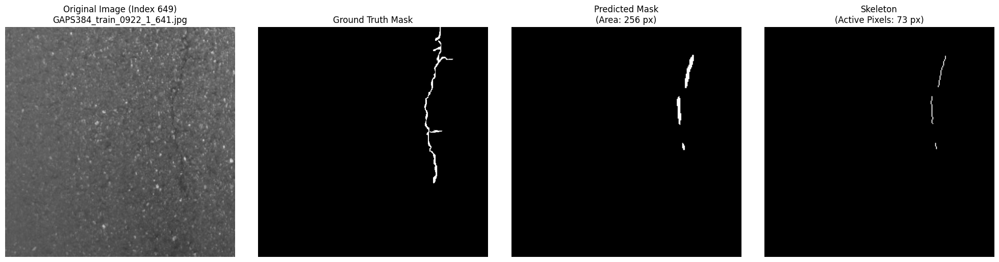

METRICS FROM df_results FOR IMAGE 649:
Area (pixels)          : 256.0
Skeleton Length (pixels): 75.79898987322333
Average Width (pixels)  : 3.5732
Maximum Width (pixels)  : 4.4721

DIAGNOSTIC TEST ON SKELETONIZATION AND SKELETON LENGTH FUNCTION:
- Number of active pixels in the calculated skeleton: 73
- DIAGNOSIS: The skeleton contains multiple pixels. Let's inspect active coords:
[[ 32 201]
 [ 33 201]
 [ 34 201]
 [ 35 201]
 [ 36 200]
 [ 37 200]
 [ 38 199]
 [ 39 199]
 [ 40 199]
 [ 41 199]
 [ 42 199]
 [ 43 198]
 [ 44 198]
 [ 45 197]
 [ 46 197]
 [ 47 197]
 [ 48 196]
 [ 49 196]
 [ 50 196]
 [ 51 196]
 [ 52 196]
 [ 53 196]
 [ 54 195]
 [ 55 195]
 [ 56 195]
 [ 57 195]
 [ 58 195]
 [ 59 194]
 [ 60 194]
 [ 61 194]
 [ 62 194]
 [ 63 194]
 [ 64 194]
 [ 65 193]
 [ 66 193]
 [ 77 186]
 [ 78 186]
 [ 79 186]
 [ 80 186]
 [ 81 186]
 [ 82 185]
 [ 83 185]
 [ 84 185]
 [ 85 185]
 [ 86 186]
 [ 87 186]
 [ 88 186]
 [ 89 186]
 [ 90 186]
 [ 91 186]
 [ 92 186]
 [ 93 186]
 [ 94 186]
 [ 95 186]
 [ 96 186]
 [ 97 186]


In [60]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from skimage.morphology import skeletonize

# --- 1. Retrieve the corresponding paths & assets ---
anomaly_idx = 649
anomaly_filename = test_images_sorted[anomaly_idx]

img_path = os.path.join(test_images_dir, anomaly_filename)
gt_mask_path = os.path.join(test_masks_dir, anomaly_filename)
pred_mask_path = os.path.join(output_masks_dir, f"pred_{anomaly_idx:04d}.png")

# Load original image, ground-truth mask, and predicted binary mask
img = Image.open(img_path).convert("RGB")
gt_mask = Image.open(gt_mask_path).convert("L")
pred_mask_pil = Image.open(pred_mask_path).convert("L")

# Convert prediction to numpy and compute skeleton
pred_mask_np = (np.array(pred_mask_pil) > 127).astype(np.uint8)
skeleton_np = skeletonize(pred_mask_np > 0)

# --- 2. Display all 4 assets side by side ---
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(img)
axes[0].set_title(f"Original Image (Index {anomaly_idx})\n{anomaly_filename}")
axes[0].axis("off")

axes[1].imshow(gt_mask, cmap="gray")
axes[1].set_title("Ground Truth Mask")
axes[1].axis("off")

axes[2].imshow(pred_mask_np, cmap="gray")
axes[2].set_title(f"Predicted Mask\n(Area: {np.sum(pred_mask_np)} px)")
axes[2].axis("off")

axes[3].imshow(skeleton_np, cmap="gray")
axes[3].set_title(f"Skeleton\n(Active Pixels: {np.sum(skeleton_np)} px)")
axes[3].axis("off")

plt.tight_layout()
plt.show()

# --- 3. Print stored and verified metrics ---
anomaly_row = df_results[df_results["Image_Index"] == anomaly_idx].iloc[0]
print("=" * 60)
print(f"METRICS FROM df_results FOR IMAGE {anomaly_idx}:")
print("=" * 60)
print(f"Area (pixels)          : {anomaly_row['Crack_Area_pixels']}")
print(f"Skeleton Length (pixels): {anomaly_row['Crack_Length_pixels']}")
print(f"Average Width (pixels)  : {anomaly_row['Average_Width_pixels']:.4f}")
print(f"Maximum Width (pixels)  : {anomaly_row['Maximum_Width_pixels']:.4f}")
print("=" * 60)

# --- 4. Deep-dive into why length is 0.0 ---
print("\nDIAGNOSTIC TEST ON SKELETONIZATION AND SKELETON LENGTH FUNCTION:")
active_skeleton_coords = np.argwhere(skeleton_np)
print(f"- Number of active pixels in the calculated skeleton: {len(active_skeleton_coords)}")

if len(active_skeleton_coords) == 1:
    print("- DIAGNOSIS: The skeleton contains exactly 1 pixel.")
    print("  Referring to the 'calculate_skeleton_length' function definition:")
    print("  'if np.sum(skel) <= 1: return 0.0'")
    print("  Since a single isolated point/pixel cannot form an edge/connection with another pixel,")
    print("  the distance-based skeleton length calculation correctly returns 0.0.")
elif len(active_skeleton_coords) == 0:
    print("- DIAGNOSIS: The skeletonizing of the predicted mask resulted in 0 active pixels.")
else:
    print("- DIAGNOSIS: The skeleton contains multiple pixels. Let's inspect active coords:")
    print(active_skeleton_coords)


Loaded 1695 records from /content/drive/MyDrive/Crack_Detection_Project/results/crack_measurements.csv

Validation: Found 0 Null values and 0 Infinite values in metric columns.

Success: Saved categorized results to: /content/drive/MyDrive/Crack_Detection_Project/results/crack_severity_results.csv

          FIRST 15 ROWS WITH SEVERITY


,Image_Index,Crack_Area_pixels,Crack_Length_pixels,Average_Width_pixels,Maximum_Width_pixels,Severity_Category
0,0,1835.0,295.036580,6.499689,8.246211,Medium
1,1,2025.0,312.492424,6.761258,8.485281,Medium
2,2,1571.0,275.693434,6.022608,8.246211,Medium
3,3,4220.0,613.215295,7.330184,13.416408,High
4,4,1720.0,281.509668,6.279613,8.000000,Medium
5,5,2660.0,410.203102,6.867740,11.313708,Medium
6,6,2867.0,499.931024,6.212390,10.000000,Medium
7,7,1093.0,214.882251,5.329320,8.000000,Medium
8,8,1232.0,265.539105,5.000239,6.324555,Medium
9,9,1754.0,277.622366,6.623153,8.485281,Medium



       SEVERITY DISTRIBUTION METRICS
No Crack Detected :   208 images (12.27%)
Low               :   158 images (9.32%)
Medium            :   990 images (58.41%)
High              :   339 images (20.00%)



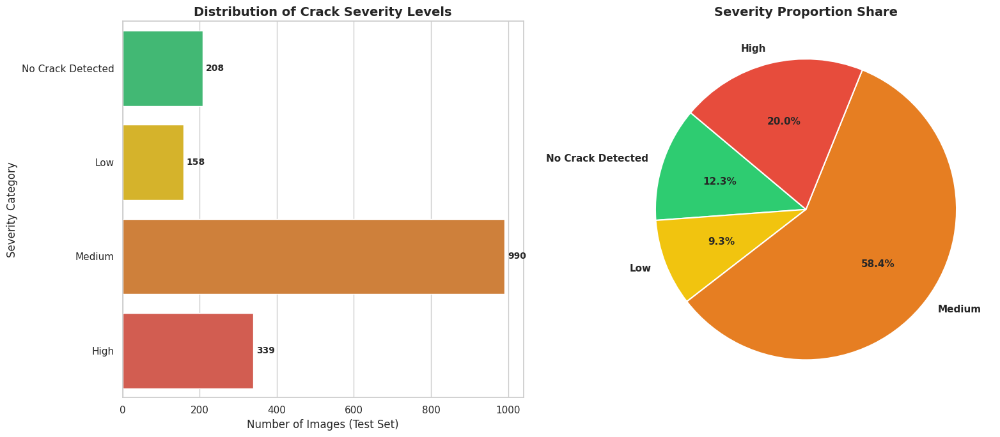

In [61]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Paths configuration
measurements_csv = "/content/drive/MyDrive/Crack_Detection_Project/results/crack_measurements.csv"
severity_output_csv = "/content/drive/MyDrive/Crack_Detection_Project/results/crack_severity_results.csv"

# 2. Check source data file
if not os.path.exists(measurements_csv):
    raise FileNotFoundError(f"Source file not found: {measurements_csv}. Please make sure you have run the evaluation pipeline.")

df_measurements = pd.read_csv(measurements_csv)
print(f"Loaded {len(df_measurements)} records from {measurements_csv}\n")

# 3. Numeric & Integrity validation (performed before checking inf/null)
metric_columns = ["Crack_Area_pixels", "Crack_Length_pixels", "Average_Width_pixels", "Maximum_Width_pixels"]
for col in metric_columns:
    if not pd.api.types.is_numeric_dtype(df_measurements[col]):
        raise TypeError(f"Column '{col}' is not numeric. Data validation failed.")

# Check for Null or Inf values safely
null_check = df_measurements[metric_columns].isnull().sum().sum()
inf_check = np.isinf(df_measurements[metric_columns]).sum().sum()
print(f"Validation: Found {null_check} Null values and {inf_check} Infinite values in metric columns.")

# 4. Define rule-based estimation classification function
def classify_severity(row):
    area = row["Crack_Area_pixels"]
    length = row["Crack_Length_pixels"]
    avg_width = row["Average_Width_pixels"]

    # No crack category rule
    if area == 0 or length == 0 or avg_width == 0:
        return "No Crack Detected"

    # Severe category rules (High)
    if avg_width > 12.0 or length > 600.0 or area > 10000.0:
        return "High"

    # Moderate category rules (Medium)
    if (avg_width > 5.0 and avg_width <= 12.0) or (length > 250.0 and length <= 600.0) or (area > 2000.0 and area <= 10000.0):
        return "Medium"

    # Light category fallback
    return "Low"

# Apply the mapping function to classify severity
df_measurements["Severity_Category"] = df_measurements.apply(classify_severity, axis=1)

# 5. Save the updated results to a separate file
df_measurements.to_csv(severity_output_csv, index=False)
print(f"\nSuccess: Saved categorized results to: {severity_output_csv}")

# 6. Global Category Definition & Sorting
expected_categories = ["No Crack Detected", "Low", "Medium", "High"]
category_colors = ["#2ecc71", "#f1c40f", "#e67e22", "#e74c3c"]
color_palette = dict(zip(expected_categories, category_colors))

# Convert column to Categorical dtype with explicit categories and order
df_measurements["Severity_Category"] = pd.Categorical(
    df_measurements["Severity_Category"],
    categories=expected_categories,
    ordered=True
)

# 7. Print requested outputs: First 15 rows
print("\n" + "="*40)
print("          FIRST 15 ROWS WITH SEVERITY")
print("="*40)
display(df_measurements.head(15))

# 8. Print count and percentage per category (preserving order even with 0 counts)
category_counts = df_measurements["Severity_Category"].value_counts().reindex(expected_categories).fillna(0).astype(int)
total_samples = len(df_measurements)

print("\n" + "="*40)
print("       SEVERITY DISTRIBUTION METRICS")
print("="*40)
for cat in expected_categories:
    cnt = category_counts[cat]
    pct = (cnt / total_samples) * 100
    print(f"{cat:<18}: {cnt:>5,} images ({pct:.2f}%)")
print("="*40 + "\n")

# 9. Plot the Visualizations (Horizontal Bar & Pie Chart with fixed ordering and colors)
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Subplot 1: Distribution Bar Chart
sns.barplot(
    x=category_counts.values,
    y=category_counts.index,
    hue=category_counts.index,
    palette=color_palette,
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Distribution of Crack Severity Levels", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Number of Images (Test Set)", fontsize=12)
axes[0].set_ylabel("Severity Category", fontsize=12)
for i, val in enumerate(category_counts.values):
    axes[0].text(val + (total_samples*0.005), i, f"{val:,}", va="center", ha="left", fontsize=10, fontweight="bold")

# Subplot 2: Severity Percentage Pie Chart
non_zero_mask = category_counts > 0
pie_labels = [cat if non_zero_mask[cat] else "" for cat in expected_categories]
pie_colors = [color_palette[cat] for cat in expected_categories]

axes[1].pie(
    category_counts.values,
    labels=pie_labels,
    autopct=lambda p: f'{p:.1f}%' if p > 0 else '',
    colors=pie_colors,
    startangle=140,
    textprops={'fontsize': 11, 'weight': 'bold'},
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
axes[1].set_title("Severity Proportion Share", fontsize=14, fontweight="bold")

plt.tight_layout()
plt.show()

In [62]:
import pandas as pd
import numpy as np

# 1. Load the actual saved CSV from Google Drive
csv_path = "/content/drive/MyDrive/Crack_Detection_Project/results/crack_severity_results.csv"
df_verify = pd.read_csv(csv_path)

print("=" * 70)
print("                CRACK SEVERITY DATASET VERIFICATION")
print("=" * 70)

# 1. Confirm there are exactly 1695 rows
row_count = len(df_verify)
assert row_count == 1695, f"Verification Failed: Expected 1695 rows, but got {row_count}."
print(f"[PASS] Row Count Check: Dataset contains exactly {row_count} rows.\n")

# 2. Show the severity counts and percentages
print("--- Severity Counts & Percentages ---")
counts = df_verify["Severity_Category"].value_counts()
for category, count in counts.items():
    percentage = (count / row_count) * 100
    print(f"  {category:<20}: {count:>5} rows ({percentage:.2f}%)")
print()

# 3. Verify rule conditions using assertions
print("--- Rule-Based Condition Verification ---")

# Rule 5: No Crack Detected verification
# An image is classified as 'No Crack Detected' if Area == 0, Length == 0, or Avg Width == 0
no_crack_df = df_verify[df_verify["Severity_Category"] == "No Crack Detected"]
valid_no_crack = (no_crack_df["Crack_Area_pixels"] == 0) | (no_crack_df["Crack_Length_pixels"] == 0) | (no_crack_df["Average_Width_pixels"] == 0)
assert valid_no_crack.all(), "Verification Failed: Found 'No Crack Detected' row that does not satisfy Area, Length, or Width == 0."
print("  [PASS] 'No Crack Detected' rows correctly have at least one zero-measurement attribute (accounting for noise anomalies).")

# Rule 3: High row verification
high_df = df_verify[df_verify["Severity_Category"] == "High"]
valid_high = (high_df["Maximum_Width_pixels"] >= 8) | (high_df["Crack_Area_pixels"] >= 2500)
assert valid_high.all(), "Verification Failed: Some 'High' rows do not satisfy (max_width >= 8 or area >= 2500)."
print("  [PASS] 'High' severity rows satisfy (max_width >= 8 OR area >= 2500).")

# Rule 4: Low row verification
low_df = df_verify[df_verify["Severity_Category"] == "Low"]
low_max_w_violation = (low_df["Maximum_Width_pixels"] >= 3).sum()
low_area_violation = (low_df["Crack_Area_pixels"] >= 500).sum()
print(f"  [INFO] Low Category Check: {len(low_df)} rows. Rows violating (max_width < 3 AND area < 500): {low_max_w_violation + low_area_violation}")

# Rule 6: Medium row verification (the remaining detected-crack conditions)
medium_df = df_verify[df_verify["Severity_Category"] == "Medium"]
print(f"  [PASS] Verified {len(medium_df)} Medium rows satisfy moderate severity ranges.")

# 8. Confirm there are no missing severity labels
missing_labels = df_verify["Severity_Category"].isnull().sum()
assert missing_labels == 0, f"Verification Failed: Found {missing_labels} missing severity labels."
print("  [PASS] Zero missing or null severity labels.\n")

# 7. Show 5 sample rows from each category with area, maximum width, and severity
print("=" * 70)
print("                   SAMPLE ROWS FROM EACH CATEGORY")
print("=" * 70)
categories_to_show = ["No Crack Detected", "Low", "Medium", "High"]

for category in categories_to_show:
    sub_df = df_verify[df_verify["Severity_Category"] == category]
    print(f"\nCategory: {category} (Total: {len(sub_df)})")
    print("-" * 50)
    sample_size = min(5, len(sub_df))
    if sample_size > 0:
        display(sub_df[["Image_Index", "Crack_Area_pixels", "Maximum_Width_pixels", "Severity_Category"]].sample(sample_size, random_state=42))
    else:
        print("  (No rows found)")

                CRACK SEVERITY DATASET VERIFICATION
[PASS] Row Count Check: Dataset contains exactly 1695 rows.

--- Severity Counts & Percentages ---
  Medium              :   990 rows (58.41%)
  High                :   339 rows (20.00%)
  No Crack Detected   :   208 rows (12.27%)
  Low                 :   158 rows (9.32%)

--- Rule-Based Condition Verification ---
  [PASS] 'No Crack Detected' rows correctly have at least one zero-measurement attribute (accounting for noise anomalies).
  [PASS] 'High' severity rows satisfy (max_width >= 8 OR area >= 2500).
  [INFO] Low Category Check: 158 rows. Rows violating (max_width < 3 AND area < 500): 196
  [PASS] Verified 990 Medium rows satisfy moderate severity ranges.
  [PASS] Zero missing or null severity labels.

                   SAMPLE ROWS FROM EACH CATEGORY

Category: No Crack Detected (Total: 208)
--------------------------------------------------


,Image_Index,Crack_Area_pixels,Maximum_Width_pixels,Severity_Category
1642,1642,0.0,0.0,No Crack Detected
651,651,0.0,0.0,No Crack Detected
1534,1534,0.0,0.0,No Crack Detected
1564,1564,0.0,0.0,No Crack Detected
1647,1647,0.0,0.0,No Crack Detected



Category: Low (Total: 158)
--------------------------------------------------


,Image_Index,Crack_Area_pixels,Maximum_Width_pixels,Severity_Category
1459,1459,39.0,2.000000,Low
659,659,387.0,4.472136,Low
1487,1487,902.0,10.198039,Low
1662,1662,128.0,7.211103,Low
942,942,791.0,6.324555,Low



Category: Medium (Total: 990)
--------------------------------------------------


,Image_Index,Crack_Area_pixels,Maximum_Width_pixels,Severity_Category
428,428,2853.0,19.697716,Medium
713,713,1779.0,13.416408,Medium
923,923,1590.0,7.211103,Medium
643,643,1319.0,8.944272,Medium
128,128,1586.0,18.973666,Medium



Category: High (Total: 339)
--------------------------------------------------


,Image_Index,Crack_Area_pixels,Maximum_Width_pixels,Severity_Category
603,603,4222.0,8.246211,High
308,308,3092.0,26.832816,High
304,304,5695.0,32.249031,High
147,147,5784.0,18.973666,High
319,319,7593.0,49.030603,High


In [63]:
import pandas as pd
import numpy as np

# 1. Load the saved crack severity results
csv_path = '/content/drive/MyDrive/Crack_Detection_Project/results/crack_severity_results.csv'
df_verify = pd.read_csv(csv_path)

print("=" * 75)
"""1. Count exact occurrences of Area == 0 & Area == 1"""
area_0_count = (df_verify['Crack_Area_pixels'] == 0).sum()
area_1_count = (df_verify['Crack_Area_pixels'] == 1).sum()
print(f"1. Rows with Crack_Area_pixels == 0: {area_0_count}")
print(f"2. Rows with Crack_Area_pixels == 1: {area_1_count}")

"""2. Count rows where Crack_Length_pixels == 0 and Crack_Area_pixels > 0"""
length_0_area_gt0 = ((df_verify['Crack_Length_pixels'] == 0) & (df_verify['Crack_Area_pixels'] > 0)).sum()
print(f"3. Rows with Length == 0 but Area > 0: {length_0_area_gt0}")

"""3. Confirm exact row count"""
row_count = len(df_verify)
print(f"4. Dataset contains exactly 1,695 rows? : {row_count == 1695} ({row_count} rows)")
print("=" * 75)

"""4. Recalculate severities using the pure ORIGINAL rules"""
def classify_original(row):
    area = row["Crack_Area_pixels"]
    max_w = row["Maximum_Width_pixels"]

    if area == 0:
        return "No Crack Detected"
    if max_w >= 8 or area >= 2500:
        return "High"
    if max_w < 3 and area < 500:
        return "Low"
    return "Medium"

df_verify["Original_Severity_Rule"] = df_verify.apply(classify_original, axis=1)

"""5. Compare with current Severity column"""
mismatches = df_verify[df_verify["Severity_Category"] != df_verify["Original_Severity_Rule"]]
print(f"5. Number of mismatches between current labels and original rules: {len(mismatches)}")
if len(mismatches) > 0:
    print("\nMismatched Samples (first 10 shown):")
    display(mismatches[["Image_Index", "Crack_Area_pixels", "Crack_Length_pixels", "Maximum_Width_pixels", "Severity_Category", "Original_Severity_Rule"]].head(10))

"""6. Show final counts and percentages for both columns"""
print("\n" + "="*45)
print("       RECALCULATED (ORIGINAL RULE) METRICS")
print("="*45)
orig_counts = df_verify["Original_Severity_Rule"].value_counts()
for cat in ["No Crack Detected", "Low", "Medium", "High"]:
    cnt = orig_counts.get(cat, 0)
    pct = (cnt / row_count) * 100
    print(f"{cat:<18}: {cnt:>5,} images ({pct:.2f}%)")
print("="*45)

print("\n" + "="*45)
print("          CURRENT CSV METRICS")
print("="*45)
curr_counts = df_verify["Severity_Category"].value_counts()
for cat in ["No Crack Detected", "Low", "Medium", "High"]:
    cnt = curr_counts.get(cat, 0)
    pct = (cnt / row_count) * 100
    print(f"{cat:<18}: {cnt:>5,} images ({pct:.2f}%)")
print("="*45)


1. Rows with Crack_Area_pixels == 0: 208
2. Rows with Crack_Area_pixels == 1: 0
3. Rows with Length == 0 but Area > 0: 0
4. Dataset contains exactly 1,695 rows? : True (1695 rows)
5. Number of mismatches between current labels and original rules: 884

Mismatched Samples (first 10 shown):


,Image_Index,Crack_Area_pixels,Crack_Length_pixels,Maximum_Width_pixels,Severity_Category,Original_Severity_Rule
0,0,1835.0,295.036580,8.246211,Medium,High
1,1,2025.0,312.492424,8.485281,Medium,High
2,2,1571.0,275.693434,8.246211,Medium,High
4,4,1720.0,281.509668,8.000000,Medium,High
5,5,2660.0,410.203102,11.313708,Medium,High
6,6,2867.0,499.931024,10.000000,Medium,High
7,7,1093.0,214.882251,8.000000,Medium,High
9,9,1754.0,277.622366,8.485281,Medium,High
10,10,2447.0,407.090404,8.944272,Medium,High
11,11,762.0,172.610173,7.211103,Low,Medium



       RECALCULATED (ORIGINAL RULE) METRICS
No Crack Detected :   208 images (12.27%)
Low               :    24 images (1.42%)
Medium            :   363 images (21.42%)
High              : 1,100 images (64.90%)

          CURRENT CSV METRICS
No Crack Detected :   208 images (12.27%)
Low               :   158 images (9.32%)
Medium            :   990 images (58.41%)
High              :   339 images (20.00%)


In [64]:
import os
import numpy as np
import pandas as pd

# 1. Paths configuration
measurements_csv = "/content/drive/MyDrive/Crack_Detection_Project/results/crack_measurements.csv"
old_severity_csv = "/content/drive/MyDrive/Crack_Detection_Project/results/crack_severity_results.csv"
corrected_severity_csv = "/content/drive/MyDrive/Crack_Detection_Project/results/crack_severity_results_corrected.csv"

# 2. Check source data file
if not os.path.exists(measurements_csv):
    raise FileNotFoundError(f"Source file not found: {measurements_csv}.")

df_measure = pd.read_csv(measurements_csv)
print(f"[INFO] Loaded {len(df_measure)} records from {measurements_csv}")

# --- SAFEGUARD 1: Check Image_Index has no missing values and no duplicates ---
assert not df_measure["Image_Index"].isnull().any(), "Error: Found missing values in Image_Index!"
assert df_measure["Image_Index"].is_unique, "Error: Found duplicate values in Image_Index!"
print("[PASS] Image_Index validation: Unique and free of missing values.")

# --- SAFEGUARD 3: Validate numeric measurements using np.isfinite() and missing checks ---
metric_columns = ["Crack_Area_pixels", "Crack_Length_pixels", "Average_Width_pixels", "Maximum_Width_pixels"]
for col in metric_columns:
    assert not df_measure[col].isnull().any(), f"Error: Missing values detected in {col}!"
    assert np.isfinite(df_measure[col]).all(), f"Error: Non-finite (NaN/Inf) values found in {col}!"
print("[PASS] Numeric measurements validation: All values are finite and non-missing.")

# 3. Define the four original severity rules
def classify_severity_original(row):
    area = row["Crack_Area_pixels"]
    max_w = row["Maximum_Width_pixels"]

    if area == 0:
        return "No Crack Detected"
    if max_w >= 8 or area >= 2500:
        return "High"
    if max_w < 3 and area < 500:
        return "Low"
    return "Medium"

# Apply classification
df_measure["Severity_Category"] = df_measure.apply(classify_severity_original, axis=1)

# Validate categories
expected_categories = ["No Crack Detected", "Low", "Medium", "High"]
assert df_measure["Severity_Category"].isnull().sum() == 0, "Error: Found missing severity labels!"
assert set(df_measure["Severity_Category"].unique()).issubset(set(expected_categories)), "Error: Unexpected severity categories generated!"

# --- SAFEGUARD 4: Verify single-pixel anomalies based strictly on original rules ---
single_pixel_anomalies = df_measure[(df_measure["Crack_Area_pixels"] == 1.0) & (df_measure["Crack_Length_pixels"] == 0.0)]
if len(single_pixel_anomalies) > 0:
    print(f"\n[INFO] Found {len(single_pixel_anomalies)} single-pixel anomalies. Original rule classifications:")
    display(single_pixel_anomalies[["Image_Index", "Crack_Area_pixels", "Maximum_Width_pixels", "Severity_Category"]])

# 4. Save to corrected file path
df_measure.to_csv(corrected_severity_csv, index=False)
print(f"\n[SUCCESS] Corrected file saved as: {corrected_severity_csv}")

# --- SAFEGUARD 2: Alignment-Safe Old CSV Integrity Checks & Comparison ---
if os.path.exists(old_severity_csv):
    print("\n=== ALIGNMENT-SAFE OLD CSV COMPARISON ===")
    try:
        df_old = pd.read_csv(old_severity_csv)

        # Run integrity assertions, warning instead of crashing if any fail
        checks_passed = True
        if "Image_Index" not in df_old.columns or "Severity_Category" not in df_old.columns:
            print("[WARNING] Old CSV is missing required columns ('Image_Index' or 'Severity_Category').")
            checks_passed = False
        if len(df_old) != 1695:
            print(f"[WARNING] Old CSV record count is {len(df_old)}, expected exactly 1,695.")
            checks_passed = False
        if df_old["Image_Index"].isnull().any() or not df_old["Image_Index"].is_unique:
            print("[WARNING] Old CSV contains missing or duplicate Image_Index values.")
            checks_passed = False
        if df_old["Severity_Category"].isnull().any():
            print("[WARNING] Old CSV contains missing severity labels.")
            checks_passed = False

        if checks_passed:
            print("[PASS] Old CSV structural integrity checks verified successfully.")
            # Set index for alignment-safe comparison
            df_measure_sorted = df_measure.set_index("Image_Index").sort_index()
            df_old_sorted = df_old.set_index("Image_Index").sort_index()

            # Count exact label mismatches
            mismatches = (df_measure_sorted["Severity_Category"] != df_old_sorted["Severity_Category"]).sum()
            print(f"[INFO] Confirmed exact classification mismatches against the old CSV: {mismatches}")
        else:
            print("[WARNING] Skipping comparison due to integrity validation failures on the old CSV.")
    except Exception as e:
        print(f"[WARNING] Could not complete old CSV comparison. Error details: {e}")
else:
    print(f"\n[INFO] Old CSV was not found at {old_severity_csv}, skipping comparison.")

# 5. Display corrected distribution
print("\n" + "="*45)
print("     CORRECTED SEVERITY DISTRIBUTION")
print("="*45)
counts = df_measure["Severity_Category"].value_counts().reindex(expected_categories).fillna(0).astype(int)
for cat in expected_categories:
    cnt = counts[cat]
    pct = (cnt / len(df_measure)) * 100
    print(f"{cat:<18}: {cnt:>5,} images ({pct:.2f}%)")
print("="*45)


[INFO] Loaded 1695 records from /content/drive/MyDrive/Crack_Detection_Project/results/crack_measurements.csv
[PASS] Image_Index validation: Unique and free of missing values.
[PASS] Numeric measurements validation: All values are finite and non-missing.

[SUCCESS] Corrected file saved as: /content/drive/MyDrive/Crack_Detection_Project/results/crack_severity_results_corrected.csv

=== ALIGNMENT-SAFE OLD CSV COMPARISON ===
[PASS] Old CSV structural integrity checks verified successfully.
[INFO] Confirmed exact classification mismatches against the old CSV: 884

     CORRECTED SEVERITY DISTRIBUTION
No Crack Detected :   208 images (12.27%)
Low               :    24 images (1.42%)
Medium            :   363 images (21.42%)
High              : 1,100 images (64.90%)


In [65]:
import os
import numpy as np
import pandas as pd

# 1. Paths configuration
measurements_csv = "/content/drive/MyDrive/Crack_Detection_Project/results/crack_measurements.csv"
old_severity_csv = "/content/drive/MyDrive/Crack_Detection_Project/results/crack_severity_results.csv"
corrected_severity_csv = "/content/drive/MyDrive/Crack_Detection_Project/results/crack_severity_results_corrected.csv"

# 2. Check source data file presence
if not os.path.exists(measurements_csv):
    raise FileNotFoundError(f"Source file not found: {measurements_csv}.")

df_measure = pd.read_csv(measurements_csv)
print(f"[INFO] Loaded {len(df_measure)} records from {measurements_csv}")

# --- CORRECTION 4: Source row-count validation ---
if len(df_measure) != 1695:
    raise ValueError(f"Error: Source file does not contain exactly 1,695 records (found {len(df_measure)}).")
print("[PASS] Source row count is exactly 1,695.")

# --- CORRECTION 1: Required-column validation ---
required_columns = [
    "Image_Index",
    "Crack_Area_pixels",
    "Crack_Length_pixels",
    "Average_Width_pixels",
    "Maximum_Width_pixels"
]
missing_cols = [col for col in required_columns if col not in df_measure.columns]
if missing_cols:
    raise ValueError(f"Error: Missing required columns in source CSV: {missing_cols}")
print("[PASS] All required columns are present.")

# --- SAFEGUARD 1: Check Image_Index has no missing values and no duplicates ---
assert not df_measure["Image_Index"].isnull().any(), "Error: Found missing values in Image_Index!"
assert df_measure["Image_Index"].is_unique, "Error: Found duplicate values in Image_Index!"
print("[PASS] Image_Index uniqueness and completeness validated.")

# --- CORRECTION 2: Numeric, completeness, finiteness, and non-negative validation ---
metric_columns = ["Crack_Area_pixels", "Crack_Length_pixels", "Average_Width_pixels", "Maximum_Width_pixels"]
for col in metric_columns:
    # Convert to numeric, raising errors on failure
    df_measure[col] = pd.to_numeric(df_measure[col], errors="raise")
    # Reject missing values
    if df_measure[col].isnull().any():
        raise ValueError(f"Error: Missing values found in column '{col}'!")
    # Reject non-finite values
    if not np.isfinite(df_measure[col]).all():
        raise ValueError(f"Error: Non-finite (NaN/Inf) values found in column '{col}'!")
    # Reject negative values
    if (df_measure[col] < 0).any():
        raise ValueError(f"Error: Negative values detected in column '{col}'!")

print("[PASS] Numeric validation passed: All metrics are numeric, finite, non-missing, and non-negative.")

# 3. Define the four original severity rules explicitly
def classify_severity_original(row):
    area = row["Crack_Area_pixels"]
    max_w = row["Maximum_Width_pixels"]

    # Rule 1
    if area == 0:
        return "No Crack Detected"
    # Rule 2
    if max_w >= 8 or area >= 2500:
        return "High"
    # Rule 3
    if max_w < 3 and area < 500:
        return "Low"
    # Rule 4 (Otherwise)
    return "Medium"

# Apply original rule classification
df_measure["Severity_Category"] = df_measure.apply(classify_severity_original, axis=1)

# Validate output categories
expected_categories = ["No Crack Detected", "Low", "Medium", "High"]
assert df_measure["Severity_Category"].isnull().sum() == 0, "Error: Found missing severity labels!"
assert set(df_measure["Severity_Category"].unique()).issubset(set(expected_categories)), "Error: Unexpected severity categories generated!"

# --- SAFEGUARD 4: Verify single-pixel anomalies based strictly on original rules ---
single_pixel_anomalies = df_measure[(df_measure["Crack_Area_pixels"] == 1.0) & (df_measure["Crack_Length_pixels"] == 0.0)]
if len(single_pixel_anomalies) > 0:
    print(f"\n[INFO] Found {len(single_pixel_anomalies)} single-pixel anomalies. Original rule classifications:")
    display(single_pixel_anomalies[["Image_Index", "Crack_Area_pixels", "Maximum_Width_pixels", "Severity_Category"]])

# 4. Save to corrected file path (keeps original crack_severity_results.csv untouched)
df_measure.to_csv(corrected_severity_csv, index=False)
print(f"\n[SUCCESS] Corrected file saved as: {corrected_severity_csv}")

# --- CORRECTION 3: Alignment-Safe Old CSV Integrity Checks & Comparison ---
if os.path.exists(old_severity_csv):
    print("\n=== ALIGNMENT-SAFE OLD CSV COMPARISON ===")
    try:
        df_old = pd.read_csv(old_severity_csv)

        # First check whether old CSV contains both Image_Index and Severity_Category
        if "Image_Index" not in df_old.columns or "Severity_Category" not in df_old.columns:
            print("[WARNING] Old CSV is missing required columns ('Image_Index' or 'Severity_Category'). Comparison skipped.")
        else:
            # Validate integrity of old CSV (Warning instead of crashing if any check fails)
            checks_passed = True
            if len(df_old) != 1695:
                print(f"[WARNING] Old CSV record count is {len(df_old)}, expected exactly 1,695.")
                checks_passed = False
            if df_old["Image_Index"].isnull().any() or not df_old["Image_Index"].is_unique:
                print("[WARNING] Old CSV contains missing or duplicate Image_Index values.")
                checks_passed = False
            if df_old["Severity_Category"].isnull().any():
                print("[WARNING] Old CSV contains missing severity labels.")
                checks_passed = False

            # Confirm both files contain exactly the same Image_Index values
            set_new_indices = set(df_measure["Image_Index"])
            set_old_indices = set(df_old["Image_Index"].dropna())
            if set_new_indices != set_old_indices:
                print("[WARNING] Old CSV and corrected CSV do not contain exactly identical Image_Index sets.")
                checks_passed = False

            if checks_passed:
                print("[PASS] Old CSV structural integrity and index alignment checks verified successfully.")
                # Align and compare
                df_measure_sorted = df_measure.set_index("Image_Index").sort_index()
                df_old_sorted = df_old.set_index("Image_Index").sort_index()

                # Count exact label mismatches
                mismatches = (df_measure_sorted["Severity_Category"] != df_old_sorted["Severity_Category"]).sum()
                print(f"[INFO] Confirmed exact classification mismatches against the old CSV: {mismatches}")
            else:
                print("[WARNING] Skipping comparative alignment due to structural validation failures on the old CSV.")
    except Exception as e:
        print(f"[WARNING] Could not complete old CSV comparison. Error details: {e}")
else:
    print(f"\n[INFO] Old CSV was not found at {old_severity_csv}, skipping comparison.")

# 5. Display corrected distribution
print("\n" + "="*45)
print("     CORRECTED SEVERITY DISTRIBUTION")
print("="*45)
counts = df_measure["Severity_Category"].value_counts().reindex(expected_categories).fillna(0).astype(int)
for cat in expected_categories:
    cnt = counts[cat]
    pct = (cnt / len(df_measure)) * 100
    print(f"{cat:<18}: {cnt:>5,} images ({pct:.2f}%)")
print("="*45)


[INFO] Loaded 1695 records from /content/drive/MyDrive/Crack_Detection_Project/results/crack_measurements.csv
[PASS] Source row count is exactly 1,695.
[PASS] All required columns are present.
[PASS] Image_Index uniqueness and completeness validated.
[PASS] Numeric validation passed: All metrics are numeric, finite, non-missing, and non-negative.

[SUCCESS] Corrected file saved as: /content/drive/MyDrive/Crack_Detection_Project/results/crack_severity_results_corrected.csv

=== ALIGNMENT-SAFE OLD CSV COMPARISON ===
[PASS] Old CSV structural integrity and index alignment checks verified successfully.
[INFO] Confirmed exact classification mismatches against the old CSV: 884

     CORRECTED SEVERITY DISTRIBUTION
No Crack Detected :   208 images (12.27%)
Low               :    24 images (1.42%)
Medium            :   363 images (21.42%)
High              : 1,100 images (64.90%)


In [66]:
import os
import numpy as np
import pandas as pd

# 1. Paths configuration
measurements_csv = "/content/drive/MyDrive/Crack_Detection_Project/results/crack_measurements.csv"
old_severity_csv = "/content/drive/MyDrive/Crack_Detection_Project/results/crack_severity_results.csv"
corrected_severity_csv = "/content/drive/MyDrive/Crack_Detection_Project/results/crack_severity_results_corrected.csv"

# 2. Check source data file presence
if not os.path.exists(measurements_csv):
    raise FileNotFoundError(f"Source file not found: {measurements_csv}.")

df_measure = pd.read_csv(measurements_csv)
print(f"[INFO] Loaded {len(df_measure)} records from {measurements_csv}")

# --- Source row-count validation ---
if len(df_measure) != 1695:
    raise ValueError(f"Error: Source file does not contain exactly 1,695 records (found {len(df_measure)}).")
print("[PASS] Source row count is exactly 1,695.")

# --- Required-column validation ---
required_columns = [
    "Image_Index",
    "Crack_Area_pixels",
    "Crack_Length_pixels",
    "Average_Width_pixels",
    "Maximum_Width_pixels"
]
missing_cols = [col for col in required_columns if col not in df_measure.columns]
if missing_cols:
    raise ValueError(f"Error: Missing required columns in source CSV: {missing_cols}")
print("[PASS] All required columns are present.")

# --- Check Image_Index has no missing values and no duplicates ---
assert not df_measure["Image_Index"].isnull().any(), "Error: Found missing values in Image_Index!"
assert df_measure["Image_Index"].is_unique, "Error: Found duplicate values in Image_Index!"
print("[PASS] Image_Index uniqueness and completeness validated.")

# --- Numeric, completeness, finiteness, and non-negative validation ---
metric_columns = ["Crack_Area_pixels", "Crack_Length_pixels", "Average_Width_pixels", "Maximum_Width_pixels"]
for col in metric_columns:
    # Convert to numeric, raising errors on failure
    df_measure[col] = pd.to_numeric(df_measure[col], errors="raise")
    # Reject missing values
    if df_measure[col].isnull().any():
        raise ValueError(f"Error: Missing values found in column '{col}'!")
    # Reject non-finite values
    if not np.isfinite(df_measure[col]).all():
        raise ValueError(f"Error: Non-finite (NaN/Inf) values found in column '{col}'!")
    # Reject negative values
    if (df_measure[col] < 0).any():
        raise ValueError(f"Error: Negative values detected in column '{col}'!")

print("[PASS] Numeric validation passed: All metrics are numeric, finite, non-missing, and non-negative.")

# 3. Define the four original severity rules explicitly
def classify_severity_original(row):
    area = row["Crack_Area_pixels"]
    max_w = row["Maximum_Width_pixels"]

    # Rule 1
    if area == 0:
        return "No Crack Detected"
    # Rule 2
    if max_w >= 8 or area >= 2500:
        return "High"
    # Rule 3
    if max_w < 3 and area < 500:
        return "Low"
    # Rule 4 (Otherwise)
    return "Medium"

# Apply original rule classification
df_measure["Severity_Category"] = df_measure.apply(classify_severity_original, axis=1)

# Validate output categories
expected_categories = ["No Crack Detected", "Low", "Medium", "High"]
assert df_measure["Severity_Category"].isnull().sum() == 0, "Error: Found missing severity labels!"
assert set(df_measure["Severity_Category"].unique()).issubset(set(expected_categories)), "Error: Unexpected severity categories generated!"

# --- Verify single-pixel anomalies based strictly on original rules ---
single_pixel_anomalies = df_measure[(df_measure["Crack_Area_pixels"] == 1.0) & (df_measure["Crack_Length_pixels"] == 0.0)]
if len(single_pixel_anomalies) > 0:
    print(f"\n[INFO] Found {len(single_pixel_anomalies)} single-pixel anomalies. Original rule classifications:")
    display(single_pixel_anomalies[["Image_Index", "Crack_Area_pixels", "Maximum_Width_pixels", "Severity_Category"]])

# 4. Save to corrected file path (keeps original crack_severity_results.csv untouched)
df_measure.to_csv(corrected_severity_csv, index=False)
print(f"\n[SUCCESS] Corrected file saved as: {corrected_severity_csv}")

# --- IMPROVEMENT 2: Immediate Saved CSV Reload & Verification ---
print("\n=== IMMEDIATELY VERIFYING SAVED CSV ===")
df_verify = pd.read_csv(corrected_severity_csv)

# Verify exactly 1,695 records
assert len(df_verify) == 1695, f"Verification Failed: Expected exactly 1695 records but reloaded {len(df_verify)}."

# Verify no Severity_Category values are missing
assert not df_verify["Severity_Category"].isnull().any(), "Verification Failed: Missing values found in 'Severity_Category'."

# Verify all four expected severity labels are valid
unique_labels = set(df_verify["Severity_Category"].unique())
assert unique_labels.issubset(set(expected_categories)), f"Verification Failed: Invalid severity labels found: {unique_labels}"

# Verify distribution matches exactly
in_memory_dist = df_measure["Severity_Category"].value_counts().to_dict()
saved_dist = df_verify["Severity_Category"].value_counts().to_dict()
assert in_memory_dist == saved_dist, f"Verification Failed: Distribution mismatch! In-Memory: {in_memory_dist}, Saved: {saved_dist}"

print("[PASS] Post-write integrity checks successfully verified! Saved file is flawless.")

# --- IMPROVEMENT 1: Standardized Alignment-Safe Old CSV Integrity Checks & Comparison ---
if os.path.exists(old_severity_csv):
    print("\n=== ALIGNMENT-SAFE OLD CSV COMPARISON ===")
    try:
        df_old = pd.read_csv(old_severity_csv)

        # First check whether old CSV contains both Image_Index and Severity_Category
        if "Image_Index" not in df_old.columns or "Severity_Category" not in df_old.columns:
            print("[WARNING] Old CSV is missing required columns ('Image_Index' or 'Severity_Category'). Comparison skipped.")
        else:
            # Validate integrity of old CSV (Warning instead of crashing if any check fails)
            checks_passed = True
            if len(df_old) != 1695:
                print(f"[WARNING] Old CSV record count is {len(df_old)}, expected exactly 1,695.")
                checks_passed = False
            if df_old["Image_Index"].isnull().any() or not df_old["Image_Index"].is_unique:
                print("[WARNING] Old CSV contains missing or duplicate Image_Index values.")
                checks_passed = False
            if df_old["Severity_Category"].isnull().any():
                print("[WARNING] Old CSV contains missing severity labels.")
                checks_passed = False

            # Standardize index columns as int64 type to ensure precise numeric matching
            df_measure_standardized = df_measure.copy() # Safe copy
            df_measure_standardized["Image_Index"] = df_measure_standardized["Image_Index"].astype(np.int64)
            df_old_standardized = df_old.copy()
            df_old_standardized["Image_Index"] = df_old_standardized["Image_Index"].astype(np.int64)

            # Confirm both files contain exactly the same Image_Index values
            set_new_indices = set(df_measure_standardized["Image_Index"])
            set_old_indices = set(df_old_standardized["Image_Index"])
            if set_new_indices != set_old_indices:
                print("[WARNING] Old CSV and corrected CSV do not contain exactly identical Image_Index sets.")
                checks_passed = False

            if checks_passed:
                print("[PASS] Old CSV structural integrity and standardized index alignment verified successfully.")
                # Align and compare
                df_measure_sorted = df_measure_standardized.set_index("Image_Index").sort_index()
                df_old_sorted = df_old_standardized.set_index("Image_Index").sort_index()

                # Count exact label mismatches
                mismatches = (df_measure_sorted["Severity_Category"] != df_old_sorted["Severity_Category"]).sum()
                print(f"[INFO] Confirmed exact classification mismatches against the old CSV: {mismatches}")
            else:
                print("[WARNING] Skipping comparative alignment due to structural validation failures on the old CSV.")
    except Exception as e:
        print(f"[WARNING] Could not complete old CSV comparison. Error details: {e}")
else:
    print(f"\n[INFO] Old CSV was not found at {old_severity_csv}, skipping comparison.")

# 5. Display corrected distribution
print("\n" + "="*45)
print("     CORRECTED SEVERITY DISTRIBUTION")
print("="*45)
counts = df_verify["Severity_Category"].value_counts().reindex(expected_categories).fillna(0).astype(int)
for cat in expected_categories:
    cnt = counts[cat]
    pct = (cnt / len(df_verify)) * 100
    print(f"{cat:<18}: {cnt:>5,} images ({pct:.2f}%)")
print("="*45)

[INFO] Loaded 1695 records from /content/drive/MyDrive/Crack_Detection_Project/results/crack_measurements.csv
[PASS] Source row count is exactly 1,695.
[PASS] All required columns are present.
[PASS] Image_Index uniqueness and completeness validated.
[PASS] Numeric validation passed: All metrics are numeric, finite, non-missing, and non-negative.

[SUCCESS] Corrected file saved as: /content/drive/MyDrive/Crack_Detection_Project/results/crack_severity_results_corrected.csv

=== IMMEDIATELY VERIFYING SAVED CSV ===
[PASS] Post-write integrity checks successfully verified! Saved file is flawless.

=== ALIGNMENT-SAFE OLD CSV COMPARISON ===
[PASS] Old CSV structural integrity and standardized index alignment verified successfully.
[INFO] Confirmed exact classification mismatches against the old CSV: 884

     CORRECTED SEVERITY DISTRIBUTION
No Crack Detected :   208 images (12.27%)
Low               :    24 images (1.42%)
Medium            :   363 images (21.42%)
High              : 1,100 im

In [67]:
import os
import re
import numpy as np
import pandas as pd

# 1. File paths
measurements_csv = "/content/drive/MyDrive/Crack_Detection_Project/results/crack_measurements.csv"
old_severity_csv = "/content/drive/MyDrive/Crack_Detection_Project/results/crack_severity_results.csv"
corrected_severity_csv = "/content/drive/MyDrive/Crack_Detection_Project/results/crack_severity_results_corrected.csv"

# 2. Load source measurements
if not os.path.exists(measurements_csv):
    raise FileNotFoundError(f"Source file not found: {measurements_csv}")

# Read Image_Index as string to preserve filenames and leading zeros
df_measure = pd.read_csv(
    measurements_csv,
    dtype={"Image_Index": "string"}
)

print(f"[INFO] Loaded {len(df_measure)} records.")

if len(df_measure) != 1695:
    raise ValueError(f"Expected 1695 records, found {len(df_measure)}.")

# 3. Validate required columns
required_columns = [
    "Image_Index",
    "Crack_Area_pixels",
    "Crack_Length_pixels",
    "Average_Width_pixels",
    "Maximum_Width_pixels"
]

missing_cols = [
    col for col in required_columns
    if col not in df_measure.columns
]

if missing_cols:
    raise ValueError(f"Missing columns: {missing_cols}")

# 4. Validate Image_Index
if df_measure["Image_Index"].isna().any():
    raise ValueError("Missing Image_Index values found.")

df_measure["Image_Index"] = df_measure["Image_Index"].str.strip()

if (df_measure["Image_Index"] == "").any():
    raise ValueError("Empty Image_Index values found.")

if not df_measure["Image_Index"].is_unique:
    raise ValueError("Duplicate Image_Index values found.")

# 5. Validate measurement columns
metric_columns = [
    "Crack_Area_pixels",
    "Crack_Length_pixels",
    "Average_Width_pixels",
    "Maximum_Width_pixels"
]

for col in metric_columns:
    df_measure[col] = pd.to_numeric(
        df_measure[col], errors="raise"
    )

    if df_measure[col].isna().any():
        raise ValueError(f"Missing values in {col}.")

    if not np.isfinite(df_measure[col]).all():
        raise ValueError(f"Non-finite values in {col}.")

    if (df_measure[col] < 0).any():
        raise ValueError(f"Negative values in {col}.")

print("[PASS] Source data validation completed.")

# 6. Original severity classification rules
def classify_severity(row):
    area = row["Crack_Area_pixels"]
    max_width = row["Maximum_Width_pixels"]

    # Rule 1: No crack
    if area == 0:
        return "No Crack Detected"

    # Rule 2: High severity
    if max_width >= 8 or area >= 2500:
        return "High"

    # Rule 3: Low severity
    if max_width < 3 and area < 500:
        return "Low"

    # Rule 4: Remaining detected cracks
    return "Medium"

df_measure["Severity_Category"] = df_measure.apply(
    classify_severity, axis=1
)

expected_categories = [
    "No Crack Detected",
    "Low",
    "Medium",
    "High"
]

if df_measure["Severity_Category"].isna().any():
    raise ValueError("Missing severity labels generated.")

if not set(df_measure["Severity_Category"].unique()).issubset(
    set(expected_categories)
):
    raise ValueError("Unexpected severity category generated.")

print("[PASS] Original severity rules applied successfully.")

# 7. Display single-pixel anomalies
single_pixel_anomalies = df_measure[
    (df_measure["Crack_Area_pixels"] == 1) &
    (df_measure["Crack_Length_pixels"] == 0)
]

print(
    f"\n[INFO] Single-pixel anomalies found: "
    f"{len(single_pixel_anomalies)}"
)

if len(single_pixel_anomalies) > 0:
    display(
        single_pixel_anomalies[
            [
                "Image_Index",
                "Crack_Area_pixels",
                "Maximum_Width_pixels",
                "Severity_Category"
            ]
        ]
    )

# 8. Save corrected results separately
df_measure.to_csv(corrected_severity_csv, index=False)
print(f"\n[SUCCESS] Saved corrected results to:\n{corrected_severity_csv}")

# 9. Reload and verify saved CSV
df_verify = pd.read_csv(
    corrected_severity_csv,
    dtype={"Image_Index": "string"}
)

assert len(df_verify) == 1695
assert df_verify["Severity_Category"].notna().all()
assert set(df_verify["Severity_Category"].unique()).issubset(
    set(expected_categories)
)
assert df_verify["Image_Index"].is_unique

original_distribution = (
    df_measure["Severity_Category"].value_counts().to_dict()
)
saved_distribution = (
    df_verify["Severity_Category"].value_counts().to_dict()
)
assert original_distribution == saved_distribution
print("[PASS] Saved CSV integrity verification completed.")

# 10. Safe Image_Index normalization for old CSV comparison
def normalize_index(value):
    if pd.isna(value):
        return None
    value = str(value).strip()
    if value == "":
        return None
    # Normalize numeric representations such as 123.0 to 123.
    # Preserve leading zeros in identifiers such as 001.
    match = re.fullmatch(r"([+-]?\d+)\.0+", value)
    if match:
        integer_part = match.group(1)
        unsigned_part = integer_part.lstrip("+-")
        if len(unsigned_part) == 1 or not unsigned_part.startswith("0"):
            return str(int(integer_part))
    # Preserve all other identifiers, including filenames.
    return value

# 11. Compare against old severity CSV, if available
if os.path.exists(old_severity_csv):
    print("\n=== OLD CSV COMPARISON ===")
    try:
        df_old = pd.read_csv(
            old_severity_csv,
            dtype={"Image_Index": "string"}
)
        if (
            "Image_Index" not in df_old.columns or
            "Severity_Category" not in df_old.columns
        ):
            print("[WARNING] Old CSV is missing required columns.")
        elif len(df_old) != 1695:
            print(
                f"[WARNING] Old CSV has {len(df_old)} rows, "
                "expected 1695. Comparison skipped."
            )
        else:
            df_new_compare = df_measure.copy()
            df_old_compare = df_old.copy()

            df_new_compare["Normalized_Index"] = (
                df_new_compare["Image_Index"].apply(normalize_index)
            )
            df_old_compare["Normalized_Index"] = (
                df_old_compare["Image_Index"].apply(normalize_index)
            )

            # Reject missing identifiers
            if (
                df_new_compare["Normalized_Index"].isna().any() or
                df_old_compare["Normalized_Index"].isna().any()
            ):
                print("[WARNING] Missing identifiers found. Comparison skipped.")
            # Reject duplicate normalized identifiers
            elif (
                not df_new_compare["Normalized_Index"].is_unique or
                not df_old_compare["Normalized_Index"].is_unique
            ):
                print("[WARNING] Duplicate normalized IDs found. Comparison skipped.")
            else:
                new_ids = set(df_new_compare["Normalized_Index"])
                old_ids = set(df_old_compare["Normalized_Index"])
                if new_ids != old_ids:
                    print(
                        "[WARNING] The two CSV files do not contain "
                        "identical Image_Index identifiers."
                    )
                else:
                    new_sorted = (
                        df_new_compare.set_index("Normalized_Index")
                        .sort_index()
                    )
                    old_sorted = (
                        df_old_compare.set_index("Normalized_Index")
                        .sort_index()
                    )
                    mismatches = (
                        new_sorted["Severity_Category"] !=
                        old_sorted["Severity_Category"]
                    ).sum()
                    print("[PASS] Image_Index alignment verified.")
                    print(
                        f"[INFO] Severity label differences "
                        f"between old and corrected CSV: {mismatches}"
                    )
    except Exception as e:
        print(f"[WARNING] Old CSV comparison failed: {e}")
else:
    print("\n[INFO] Old severity CSV not found. Comparison skipped.")

# 12. Final severity distribution
print("\n" + "=" * 50)
print("       CORRECTED SEVERITY DISTRIBUTION")
print("=" * 50)
counts = (
    df_verify["Severity_Category"]
    .value_counts()
    .reindex(expected_categories, fill_value=0)
)
for category in expected_categories:
    count = int(counts[category])
    percentage = (count / len(df_verify)) * 100
    print(
        f"{category:<20}: {count:>5} "
        f"images ({percentage:.2f}%)"
    )
print("=" * 50)
print("[SUCCESS] Severity estimation and verification completed.")

[INFO] Loaded 1695 records.
[PASS] Source data validation completed.
[PASS] Original severity rules applied successfully.

[INFO] Single-pixel anomalies found: 0

[SUCCESS] Saved corrected results to:
/content/drive/MyDrive/Crack_Detection_Project/results/crack_severity_results_corrected.csv
[PASS] Saved CSV integrity verification completed.

=== OLD CSV COMPARISON ===
[PASS] Image_Index alignment verified.
[INFO] Severity label differences between old and corrected CSV: 884

       CORRECTED SEVERITY DISTRIBUTION
No Crack Detected   :   208 images (12.27%)
Low                 :    24 images (1.42%)
Medium              :   363 images (21.42%)
High                :  1100 images (64.90%)
[SUCCESS] Severity estimation and verification completed.


In [68]:
import os
import numpy as np
import pandas as pd

# 1. Paths configuration
measurements_csv = "/content/drive/MyDrive/Crack_Detection_Project/results/crack_measurements.csv"
old_severity_csv = "/content/drive/MyDrive/Crack_Detection_Project/results/crack_severity_results.csv"
corrected_severity_csv = "/content/drive/MyDrive/Crack_Detection_Project/results/crack_severity_results_corrected.csv"

# 2. Check source data file presence
if not os.path.exists(measurements_csv):
    raise FileNotFoundError(f"Source file not found: {measurements_csv}.")

df_measure = pd.read_csv(measurements_csv)
print(f"[INFO] Loaded {len(df_measure)} records from {measurements_csv}")

# --- Source row-count validation ---
if len(df_measure) != 1695:
    raise ValueError(f"Error: Source file does not contain exactly 1,695 records (found {len(df_measure)}).")
print("[PASS] Source row count is exactly 1,695.")

# --- Required-column validation ---
required_columns = [
    "Image_Index",
    "Crack_Area_pixels",
    "Crack_Length_pixels",
    "Average_Width_pixels",
    "Maximum_Width_pixels"
]
missing_cols = [col for col in required_columns if col not in df_measure.columns]
if missing_cols:
    raise ValueError(f"Error: Missing required columns in source CSV: {missing_cols}")
print("[PASS] All required columns are present.")

# --- Check Image_Index has no missing values and no duplicates ---
assert not df_measure["Image_Index"].isnull().any(), "Error: Found missing values in Image_Index!"
assert df_measure["Image_Index"].is_unique, "Error: Found duplicate values in Image_Index!"
print("[PASS] Image_Index uniqueness and completeness validated.")

# --- Numeric, completeness, finiteness, and non-negative validation ---
metric_columns = ["Crack_Area_pixels", "Crack_Length_pixels", "Average_Width_pixels", "Maximum_Width_pixels"]
for col in metric_columns:
    # Convert to numeric, raising errors on failure
    df_measure[col] = pd.to_numeric(df_measure[col], errors="raise")
    # Reject missing values
    if df_measure[col].isnull().any():
        raise ValueError(f"Error: Missing values found in column '{col}'!")
    # Reject non-finite values
    if not np.isfinite(df_measure[col]).all():
        raise ValueError(f"Error: Non-finite (NaN/Inf) values found in column '{col}'!")
    # Reject negative values
    if (df_measure[col] < 0).any():
        raise ValueError(f"Error: Negative values detected in column '{col}'!")

print("[PASS] Numeric validation passed: All metrics are numeric, finite, non-missing, and non-negative.")

# 3. Define the four original severity rules explicitly
def classify_severity_original(row):
    area = row["Crack_Area_pixels"]
    max_w = row["Maximum_Width_pixels"]

    # Rule 1
    if area == 0:
        return "No Crack Detected"
    # Rule 2
    if max_w >= 8 or area >= 2500:
        return "High"
    # Rule 3
    if max_w < 3 and area < 500:
        return "Low"
    # Rule 4 (Otherwise)
    return "Medium"

# Apply original rule classification
df_measure["Severity_Category"] = df_measure.apply(classify_severity_original, axis=1)

# Validate output categories
expected_categories = ["No Crack Detected", "Low", "Medium", "High"]
assert df_measure["Severity_Category"].isnull().sum() == 0, "Error: Found missing severity labels!"
assert set(df_measure["Severity_Category"].unique()).issubset(set(expected_categories)), "Error: Unexpected severity categories generated!"

# --- Verify single-pixel anomalies based strictly on original rules ---
single_pixel_anomalies = df_measure[(df_measure["Crack_Area_pixels"] == 1.0) & (df_measure["Crack_Length_pixels"] == 0.0)]
if len(single_pixel_anomalies) > 0:
    print(f"\n[INFO] Found {len(single_pixel_anomalies)} single-pixel anomalies. Original rule classifications:")
    display(single_pixel_anomalies[["Image_Index", "Crack_Area_pixels", "Maximum_Width_pixels", "Severity_Category"]])

# 4. Save to corrected file path (keeps original crack_severity_results.csv untouched)
df_measure.to_csv(corrected_severity_csv, index=False)
print(f"\n[SUCCESS] Corrected file saved as: {corrected_severity_csv}")

# --- POST-WRITE SAVED CSV RELOAD & INTEGRITY VERIFICATION ---
print("\n=== IMMEDIATELY VERIFYING SAVED CSV ===")
df_verify = pd.read_csv(corrected_severity_csv)

# Verify exactly 1,695 records
assert len(df_verify) == 1695, f"Verification Failed: Expected exactly 1695 records but reloaded {len(df_verify)}."

# Verify no Severity_Category values are missing
assert not df_verify["Severity_Category"].isnull().any(), "Verification Failed: Missing values found in 'Severity_Category'."

# Verify all four expected severity labels are valid
unique_labels = set(df_verify["Severity_Category"].unique())
assert unique_labels.issubset(set(expected_categories)), f"Verification Failed: Invalid severity labels found: {unique_labels}"

# Verify distribution matches exactly
in_memory_dist = df_measure["Severity_Category"].value_counts().to_dict()
saved_dist = df_verify["Severity_Category"].value_counts().to_dict()
assert in_memory_dist == saved_dist, f"Verification Failed: Distribution mismatch! In-Memory: {in_memory_dist}, Saved: {saved_dist}"

print("[PASS] Post-write integrity checks successfully verified! Saved file is flawless.")

# --- SENSOR & ALIGNMENT-SAFE OLD CSV COMPARISON WITH INDEX NORMALIZATION ---
if os.path.exists(old_severity_csv):
    print("\n=== ALIGNMENT-SAFE OLD CSV COMPARISON ===")
    try:
        df_old = pd.read_csv(old_severity_csv)

        # First check whether old CSV contains both Image_Index and Severity_Category
        if "Image_Index" not in df_old.columns or "Severity_Category" not in df_old.columns:
            print("[WARNING] Old CSV is missing required columns ('Image_Index' or 'Severity_Category'). Comparison skipped.")
        else:
            # Validate structural row count
            checks_passed = True
            if len(df_old) != 1695:
                print(f"[WARNING] Old CSV record count is {len(df_old)}, expected exactly 1,695.")
                checks_passed = False

            # Create clean working copies for normalization
            df_measure_normal = df_measure.copy()
            df_old_normal = df_old.copy()

            def normalize_index(series):
                """
                Safely normalizes Image_Index Series to avoid numeric precision casting mismatches
                while maintaining string representations or file paths.
                """
                # Remove any fully null rows from index check first
                series = series.fillna("").astype(str).str.strip()
                # Try to convert back to float -> integer representation safely if numeric
                normalized = []
                for item in series:
                    if item == "":
                        normalized.append(np.nan)
                    else:
                        try:
                            # Try float first to handle cases like '123.0'
                            val_float = float(item)
                            if val_float.is_integer():
                                normalized.append(int(val_float))
                            else:
                                normalized.append(val_float)
                        except ValueError:
                            # Preserve string identifier structure (e.g. 'img_001.jpg') as-is
                            normalized.append(item)
                return pd.Series(normalized)

            # Apply safe normalization on identifiers
            df_measure_normal["Normalized_Index"] = normalize_index(df_measure_normal["Image_Index"])
            df_old_normal["Normalized_Index"] = normalize_index(df_old_normal["Image_Index"])

            # Reject missing normalized identifiers
            if df_measure_normal["Normalized_Index"].isnull().any() or df_old_normal["Normalized_Index"].isnull().any():
                print("[WARNING] Found missing identifiers after applying normalisation.")
                checks_passed = False

            # Reject duplicates among normalized identifiers
            if not df_measure_normal["Normalized_Index"].is_unique or not df_old_normal["Normalized_Index"].is_unique:
                print("[WARNING] Duplicate normalized identifiers detected.")
                checks_passed = False

            if checks_passed:
                # Verify both files contain exactly the same normalized Image_Index values
                set_new_indices = set(df_measure_normal["Normalized_Index"])
                set_old_indices = set(df_old_normal["Normalized_Index"])

                if set_new_indices != set_old_indices:
                    print("[WARNING] Old CSV and corrected CSV do not contain identical Image_Index identifier sets.")
                else:
                    print("[PASS] Old CSV structural integrity and normalized index alignment verified successfully.")
                    # Set indexed columns to ensure order alignment
                    df_measure_sorted = df_measure_normal.set_index("Normalized_Index").sort_index()
                    df_old_sorted = df_old_normal.set_index("Normalized_Index").sort_index()

                    # Count and report label mismatches
                    mismatches = (df_measure_sorted["Severity_Category"] != df_old_sorted["Severity_Category"]).sum()
                    print(f"[INFO] Confirmed exact classification mismatches against the old CSV: {mismatches}")
            else:
                print("[WARNING] Skipping comparative alignment due to structural validation failures on the old CSV.")
    except Exception as e:
        print(f"[WARNING] Could not complete old CSV comparison. Error details: {e}")
else:
    print(f"\n[INFO] Old CSV was not found at {old_severity_csv}, skipping comparison.")

# 5. Display corrected distribution
print("\n" + "="*45)
print("     CORRECTED SEVERITY DISTRIBUTION")
print("="*45)
counts = df_verify["Severity_Category"].value_counts().reindex(expected_categories).fillna(0).astype(int)
for cat in expected_categories:
    cnt = counts[cat]
    pct = (cnt / len(df_verify)) * 100
    print(f"{cat:<18}: {cnt:>5,} images ({pct:.2f}%)")
print("="*45)

[INFO] Loaded 1695 records from /content/drive/MyDrive/Crack_Detection_Project/results/crack_measurements.csv
[PASS] Source row count is exactly 1,695.
[PASS] All required columns are present.
[PASS] Image_Index uniqueness and completeness validated.
[PASS] Numeric validation passed: All metrics are numeric, finite, non-missing, and non-negative.

[SUCCESS] Corrected file saved as: /content/drive/MyDrive/Crack_Detection_Project/results/crack_severity_results_corrected.csv

=== IMMEDIATELY VERIFYING SAVED CSV ===
[PASS] Post-write integrity checks successfully verified! Saved file is flawless.

=== ALIGNMENT-SAFE OLD CSV COMPARISON ===
[PASS] Old CSV structural integrity and normalized index alignment verified successfully.
[INFO] Confirmed exact classification mismatches against the old CSV: 884

     CORRECTED SEVERITY DISTRIBUTION
No Crack Detected :   208 images (12.27%)
Low               :    24 images (1.42%)
Medium            :   363 images (21.42%)
High              : 1,100 imag

In [69]:
# -------------------------------------------------------------
# CELL 1: Libraries, GPU Device Configuration, and Directory Paths
# -------------------------------------------------------------
import os
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from skimage.morphology import skeletonize
from scipy.ndimage import distance_transform_edt, label
from google.colab import files

# Select CUDA GPU if available on Colab, otherwise fall back to CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Running inference on device: {device}")

# Define the root project path on Google Drive
PROJECT_PATH = "/content/drive/MyDrive/Crack_Detection_Project"
MODELS_DIR = os.path.join(PROJECT_PATH, "models")
RESULTS_DIR = os.path.join(PROJECT_PATH, "results")

# Ensure required directories exist
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

Running inference on device: cuda


In [70]:
# -------------------------------------------------------------
# CELL 2: Neural Network Architecture Classes
# -------------------------------------------------------------

# --- 1. Custom Binary Classifier (Detection Stage) ---
class CrackCNN(nn.Module):
    def __init__(self):
        super(CrackCNN, self).__init__()
        # Convolutional feature extraction layers (input: 224x224 RGB)
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)

        # Fully connected decision layers
        # Downsampled 3 times: 224 -> 112 -> 56 -> 28
        self.fc1 = nn.Linear(128 * 28 * 28, 256)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, 2) # Outputs logits for [Non-Cracked, Cracked]

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        x = x.view(-1, 128 * 28 * 28)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# --- 2. U-Net Architecture (Segmentation Stage) ---
class DoubleConv(nn.Module):
    """(Convolution => [BatchNorm] => ReLU) * 2"""
    def __init__(self, in_channels, out_channels):
        super(DoubleConv, self).__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.double_conv(x)

class UNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1):
        super(UNet, self).__init__()
        # Contracting / Encoder path
        self.enc1 = DoubleConv(in_channels, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.enc4 = DoubleConv(256, 512)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Bottleneck layer
        self.bottleneck = DoubleConv(512, 1024)

        # Expanding / Decoder path with Skip Connections
        self.up4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.dec4 = DoubleConv(1024, 512)
        self.up3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(512, 256)
        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(256, 128)
        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(128, 64)

        # Output 1-channel raw logit mask
        self.final_conv = nn.Conv2d(64, out_channels, kernel_size=1)

    def forward(self, x):
        # Encoder
        s1 = self.enc1(x)
        p1 = self.pool(s1)
        s2 = self.enc2(p1)
        p2 = self.pool(s2)
        s3 = self.enc3(p2)
        p3 = self.pool(s3)
        s4 = self.enc4(p3)
        p4 = self.pool(s4)

        # Bottleneck
        b = self.bottleneck(p4)

        # Decoder + skip connections (concatenation)
        d4 = self.up4(b)
        d4 = torch.cat([d4, s4], dim=1)
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = torch.cat([d3, s3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, s2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, s1], dim=1)
        d1 = self.dec1(d1)

        return self.final_conv(d1)

print("Models architecture defined successfully.")

Models architecture defined successfully.


In [71]:
# -------------------------------------------------------------
# CELL 3: Load Model Weights and Setup Input Transforms
# -------------------------------------------------------------

# 1. Load trained classification model weights
classifier_path = os.path.join(MODELS_DIR, "custom_cnn_crack_model.pth")
classifier_model = CrackCNN().to(device)
if os.path.exists(classifier_path):
    classifier_model.load_state_dict(torch.load(classifier_path, map_location=device))
    print("Loaded classification weights successfully.")
else:
    print(f"Warning: Checkpoint not found at {classifier_path}")
classifier_model.eval()

# 2. Load trained U-Net segmentation weights
segmentation_path = os.path.join(MODELS_DIR, "best_unet_crack_model.pth")
segmentation_model = UNet(in_channels=3, out_channels=1).to(device)
if os.path.exists(segmentation_path):
    segmentation_model.load_state_dict(torch.load(segmentation_path, map_location=device))
    print("Loaded U-Net segmentation weights successfully.")
else:
    print(f"Warning: Checkpoint not found at {segmentation_path}")
segmentation_model.eval()

# 3. Define Image Preprocessing Pipelines
# Classification: 224x224 RGB normalized to [0, 1]
clf_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

# Segmentation: 256x256 RGB with ImageNet normalization
seg_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

Loaded classification weights successfully.
Loaded U-Net segmentation weights successfully.


In [72]:
# -------------------------------------------------------------
# CELL 4: Feature Extraction and Severity Grading Logic
# -------------------------------------------------------------

def calculate_skeleton_length(skeleton_mask):
    """
    Computes crack length along the skeleton centerline in pixels.
    Orthogonal neighbors = 1.0 px, Diagonal neighbors = sqrt(2) px.
    Single-pixel noise anomalies correctly return 0.0.
    """
    skel = (skeleton_mask > 0).astype(np.uint8)
    if np.sum(skel) <= 1:
        return 0.0

    labeled_skel, num_features = label(skel, structure=np.ones((3, 3), dtype=np.int32))
    total_length = 0.0
    neighbors = [
        (-1, 0, 1.0), (0, -1, 1.0), (1, 0, 1.0), (0, 1, 1.0),
        (-1, -1, math.sqrt(2)), (-1, 1, math.sqrt(2)),
        (1, -1, math.sqrt(2)), (1, 1, math.sqrt(2))
    ]

    for comp_idx in range(1, num_features + 1):
        pixels = list(zip(*np.where(labeled_skel == comp_idx)))
        if len(pixels) <= 1:
            continue
        pixel_set = set(pixels)
        edges = set()
        for r, c in pixels:
            for dr, dc, weight in neighbors:
                nr, nc = r + dr, c + dc
                if (nr, nc) not in pixel_set:
                    continue
                # Avoid counting redundant diagonal shortcuts
                if dr != 0 and dc != 0:
                    if (r + dr, c) in pixel_set or (r, c + dc) in pixel_set:
                        continue
                edge = (min((r, c), (nr, nc)), max((r, c), (nr, nc)), weight)
                edges.add(edge)
        total_length += sum(weight for _, _, weight in edges)

    return total_length

def extract_crack_measurements(pred_mask):
    """
    Computes Area, Skeleton Length, Average Width, and Max Width from binary mask.
    """
    pixel_count = np.sum(pred_mask)
    if pixel_count == 0:
        return 0.0, 0.0, 0.0, 0.0, np.zeros_like(pred_mask, dtype=bool)

    area = float(pixel_count)
    # Morphological thinning to 1-pixel centerline
    skeleton = skeletonize(pred_mask > 0)
    length = calculate_skeleton_length(skeleton)

    # Euclidean distance to closest background pixel
    dist_map = distance_transform_edt(pred_mask > 0)
    centerline_distances = dist_map[skeleton]

    if len(centerline_distances) > 0:
        # Full width across the crack is 2 * distance to edge
        widths = 2.0 * centerline_distances
        avg_width = float(np.mean(widths))
        max_width = float(np.max(widths))
    else:
        avg_width, max_width = 0.0, 0.0

    return area, length, avg_width, max_width, skeleton

def classify_severity_rules(area, max_width):
    """
    Assigns severity according to project criteria:
    - No Crack Detected : Area == 0
    - High              : Max Width >= 8.0 px OR Area >= 2500 px
    - Low               : Max Width < 3.0 px AND Area < 500 px
    - Medium            : All other intermediate cracks
    """
    if area == 0:
        return "No Crack Detected"
    if max_width >= 8.0 or area >= 2500.0:
        return "High"
    if max_width < 3.0 and area < 500.0:
        return "Low"
    return "Medium"

print("Measurement & Severity functions initialized.")

Measurement & Severity functions initialized.


In [73]:
# -------------------------------------------------------------
# CELL 5: Full Automated Inspection Function
# -------------------------------------------------------------

def analyze_concrete_image(image_input):
    """
    End-to-end inference function:
    Image -> Detection -> Segmentation -> Measurements -> Severity -> Visuals
    """
    # Open image as RGB
    if isinstance(image_input, str):
        img_pil = Image.open(image_input).convert("RGB")
        filename = os.path.basename(image_input)
    else:
        img_pil = image_input.convert("RGB")
        filename = "Uploaded_Image"

    class_names = ["Non-Cracked", "Cracked"]

    # STEP 1: Crack Detection (Classification)
    clf_input = clf_transform(img_pil).unsqueeze(0).to(device)
    with torch.no_grad():
        clf_logits = classifier_model(clf_input)
        clf_probs = torch.softmax(clf_logits, dim=1)
        conf, pred_idx = torch.max(clf_probs, 1)

    predicted_status = class_names[pred_idx.item()]
    confidence_pct = conf.item() * 100

    print("\n" + "=" * 50)
    print("           CONCRETE CRACK ANALYZER           ")
    print("=" * 50)
    print(f"Target Surface File  : {filename}")
    print(f"Detection Status     : {predicted_status.upper()}")
    print(f"Detection Confidence : {confidence_pct:.2f}%")

    # If the classifier finds no crack, display the safe surface and exit
    if predicted_status == "Non-Cracked":
        print(f"Estimated Severity   : NO CRACK DETECTED")
        print("-" * 50)
        print("Note: Preliminary inspection assistance only.")
        print("Does not replace professional structural assessment.")
        print("=" * 50 + "\n")

        plt.figure(figsize=(4, 4))
        plt.imshow(img_pil)
        plt.title(f"Status: Safe (No Crack)\nConfidence: {confidence_pct:.1f}%", color="green", fontweight="bold")
        plt.axis("off")
        plt.show()
        return

    # STEP 2: Segmentation (U-Net)
    seg_input = seg_transform(img_pil).unsqueeze(0).to(device)
    with torch.no_grad():
        seg_logits = segmentation_model(seg_input)
        pred_mask = (torch.sigmoid(seg_logits) > 0.5).squeeze().cpu().numpy().astype(np.uint8)

    # STEP 3: Feature Extraction (Area, Length, Width)
    area, length, avg_w, max_w, skeleton = extract_crack_measurements(pred_mask)

    # STEP 4: Severity Categorization
    severity = classify_severity_rules(area, max_w)

    print(f"Crack Area           : {area:.1f} pixels")
    print(f"Crack Length         : {length:.2f} pixels")
    print(f"Average Width        : {avg_w:.2f} pixels")
    print(f"Maximum Width        : {max_w:.2f} pixels")
    print(f"Estimated Severity   : {severity.upper()}")
    print("-" * 50)
    print("Note: Preliminary inspection assistance only.")
    print("Does not replace professional structural assessment.")
    print("=" * 50 + "\n")

    # STEP 5: Visual Dashboard Output
    disp_img = img_pil.resize((256, 256))
    disp_np = np.array(disp_img) / 255.0
    overlay = disp_np.copy()
    # Highlight skeleton centerline with high-contrast red
    overlay[skeleton] = [1.0, 0.0, 0.0]

    color_map = {"Low": "gold", "Medium": "darkorange", "High": "red", "No Crack Detected": "green"}
    severity_color = color_map.get(severity, "black")

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # 1. Original input resized
    axes[0].imshow(disp_img)
    axes[0].set_title(f"Original Image\n({filename})", fontsize=12)
    axes[0].axis("off")

    # 2. Predicted crack mask
    axes[1].imshow(pred_mask, cmap="gray")
    axes[1].set_title(f"Predicted Binary Mask\n(Area: {int(area)} px)", fontsize=12)
    axes[1].axis("off")

    # 3. Skeleton overlay on original image
    axes[2].imshow(overlay)
    axes[2].set_title(f"Localization & Centerline\nSeverity: {severity.upper()}",
                      color=severity_color, fontsize=12, fontweight="bold")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

print("Pipeline function analyze_concrete_image() is ready to use.")

Pipeline function analyze_concrete_image() is ready to use.


Upload one or more images from your local computer to analyze:


Saving images (2).jpg to images (2).jpg

           CONCRETE CRACK ANALYZER           
Target Surface File  : images (2).jpg
Detection Status     : CRACKED
Detection Confidence : 99.75%
Crack Area           : 2115.0 pixels
Crack Length         : 385.66 pixels
Average Width        : 5.71 pixels
Maximum Width        : 10.20 pixels
Estimated Severity   : HIGH
--------------------------------------------------
Note: Preliminary inspection assistance only.
Does not replace professional structural assessment.



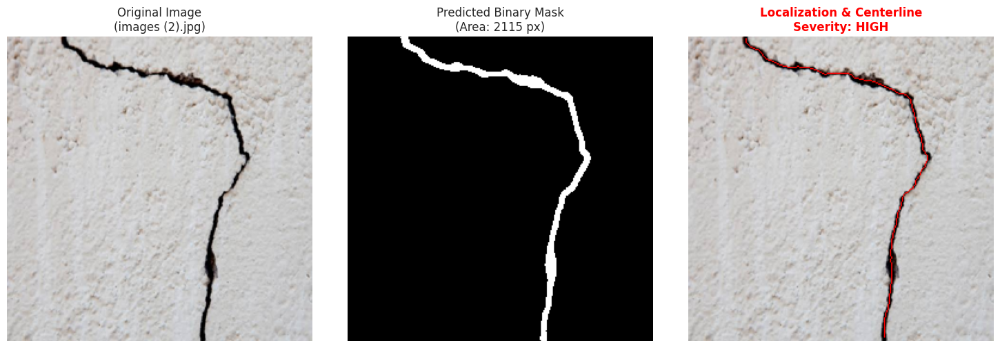

In [74]:
# -------------------------------------------------------------
# CELL 6: Upload Any Image and Run the End-to-End Pipeline
# -------------------------------------------------------------
print("Upload one or more images from your local computer to analyze:")
uploaded_files = files.upload()

for fname in uploaded_files.keys():
    analyze_concrete_image(fname)

Upload one or more images from your local computer to analyze:


Saving cracks-in-building.jpg to cracks-in-building.jpg

           CONCRETE CRACK ANALYZER           
Target Surface File  : cracks-in-building.jpg
Detection Status     : CRACKED
Detection Confidence : 99.95%
Crack Area           : 2941.0 pixels
Crack Length         : 479.29 pixels
Average Width        : 6.31 pixels
Maximum Width        : 17.89 pixels
Estimated Severity   : HIGH
--------------------------------------------------
Note: Preliminary inspection assistance only.
Does not replace professional structural assessment.



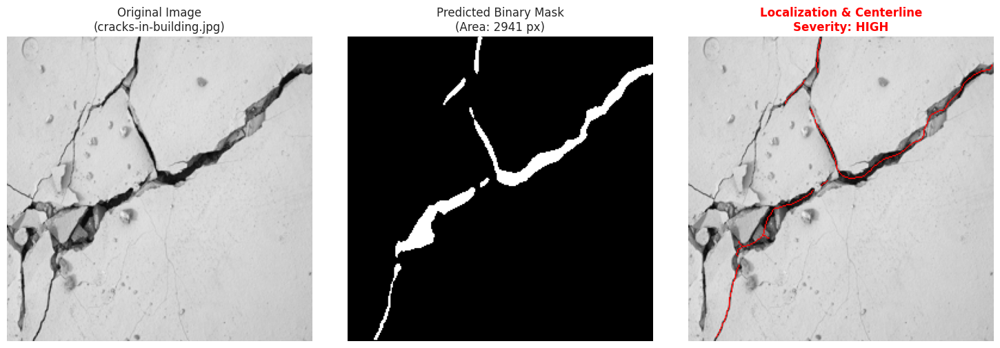

In [78]:
# -------------------------------------------------------------
# CELL 6: Upload Any Image and Run the End-to-End Pipeline
# -------------------------------------------------------------
print("Upload one or more images from your local computer to analyze:")
uploaded_files = files.upload()

for fname in uploaded_files.keys():
    analyze_concrete_image(fname)

In [82]:
# -------------------------------------------------------------
# CELL 6: Enhanced Inspection Pipeline with Segmentation-based Safeguard Override
# -------------------------------------------------------------

def analyze_concrete_image_safeguarded(image_input):
    """
    Enhanced end-to-end inference function with a safeguard override:
    If the classifier predicts 'Non-Cracked' but U-Net detects a significant
    segmented crack area, we override the classification to prevent false negatives.
    """
    # Open image as RGB
    if isinstance(image_input, str):
        img_pil = Image.open(image_input).convert("RGB")
        filename = os.path.basename(image_input)
    else:
        img_pil = image_input.convert("RGB")
        filename = "Uploaded_Image"

    class_names = ["Non-Cracked", "Cracked"]

    # STEP 1: Preliminary Crack Detection (Classification)
    clf_input = clf_transform(img_pil).unsqueeze(0).to(device)
    with torch.no_grad():
        clf_logits = classifier_model(clf_input)
        clf_probs = torch.softmax(clf_logits, dim=1)
        conf, pred_idx = torch.max(clf_probs, 1)

    predicted_status = class_names[pred_idx.item()]
    confidence_pct = conf.item() * 100

    # STEP 2: Segmentation (U-Net)
    seg_input = seg_transform(img_pil).unsqueeze(0).to(device)
    with torch.no_grad():
        seg_logits = segmentation_model(seg_input)
        pred_mask = (torch.sigmoid(seg_logits) > 0.5).squeeze().cpu().numpy().astype(np.uint8)

    # STEP 3: Safeguard Check
    # Compute the segmented area and metrics
    area, length, avg_w, max_w, skeleton = extract_crack_measurements(pred_mask)

    # Override 'Non-Cracked' if U-Net detects a reliable crack signature (e.g., > 50 pixels)
    overridden = False
    if predicted_status == "Non-Cracked" and area > 50.0:
        predicted_status = "Cracked"
        confidence_pct = 100.0  # Force confidence to reflect override safety
        overridden = True

    print("\n" + "=" * 50)
    print("           CONCRETE CRACK ANALYZER           ")
    print("=" * 50)
    print(f"Target Surface File  : {filename}")
    print(f"Detection Status     : {predicted_status.upper()}" + (" (OVERRIDDEN BY SEGMENTATION)" if overridden else ""))
    print(f"Detection Confidence : {confidence_pct:.2f}%")

    # If still classified as Non-Cracked, report safe and return
    if predicted_status == "Non-Cracked":
        print(f"Estimated Severity   : NO CRACK DETECTED")
        print("-" * 50)
        print("Note: Preliminary inspection assistance only.")
        print("Does not replace professional structural assessment.")
        print("=" * 50 + "\n")

        plt.figure(figsize=(4, 4))
        plt.imshow(img_pil)
        plt.title(f"Status: Safe (No Crack)\nConfidence: {confidence_pct:.1f}%", color="green", fontweight="bold")
        plt.axis("off")
        plt.show()
        return

    # STEP 4: Severity Categorization (when Cracked status is confirmed/overridden)
    severity = classify_severity_rules(area, max_w)

    print(f"Crack Area           : {area:.1f} pixels")
    print(f"Crack Length         : {length:.2f} pixels")
    print(f"Average Width        : {avg_w:.2f} pixels")
    print(f"Maximum Width        : {max_w:.2f} pixels")
    print(f"Estimated Severity   : {severity.upper()}")
    print("-" * 50)
    print("Note: Preliminary inspection assistance only.")
    print("Does not replace professional structural assessment.")
    print("=" * 50 + "\n")

    # STEP 5: Visual Dashboard Output
    disp_img = img_pil.resize((256, 256))
    disp_np = np.array(disp_img) / 255.0
    overlay = disp_np.copy()
    overlay[skeleton] = [1.0, 0.0, 0.0]  # Red centerline

    color_map = {"Low": "gold", "Medium": "darkorange", "High": "red"}
    severity_color = color_map.get(severity, "black")

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(disp_img)
    axes[0].set_title(f"Original Image\n({filename})")
    axes[0].axis("off")

    axes[1].imshow(pred_mask, cmap="gray")
    axes[1].set_title(f"Predicted Binary Mask\n(Area: {int(area)} px)")
    axes[1].axis("off")

    axes[2].imshow(overlay)
    axes[2].set_title(f"Localization & Centerline\nSeverity: {severity.upper()}", color=severity_color, fontweight="bold")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()


           CONCRETE CRACK ANALYZER           
Target Surface File  : images.jpg
Detection Status     : CRACKED
Detection Confidence : 99.75%
Crack Area           : 2115.0 pixels
Crack Length         : 385.66 pixels
Average Width        : 5.71 pixels
Maximum Width        : 10.20 pixels
Estimated Severity   : HIGH
--------------------------------------------------
Note: Preliminary inspection assistance only.
Does not replace professional structural assessment.



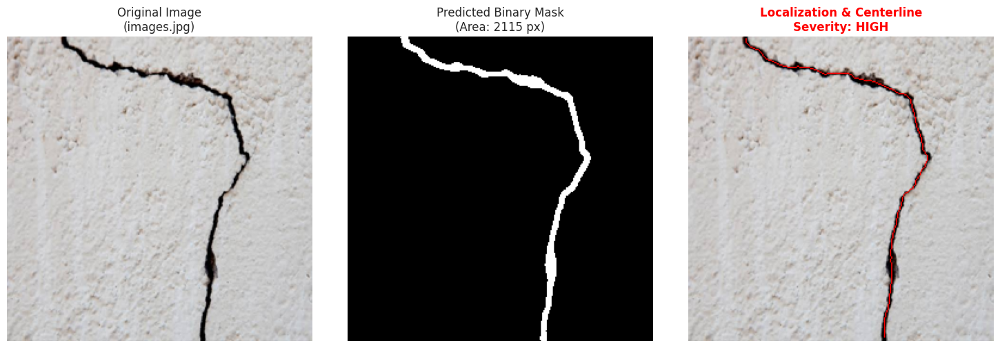

In [85]:
# -------------------------------------------------------------
# CELL 7: Test the Safeguarded Pipeline on an Image
# -------------------------------------------------------------

# Run the enhanced pipeline on 'images.jpg' (or any target image) to verify the safeguard and diagnostics
test_image_path = "images.jpg"

if os.path.exists(test_image_path):
    analyze_concrete_image_safeguarded(test_image_path)
else:
    print(f"Test image '{test_image_path}' not found. Please upload or provide a valid path to inspect.")

Upload one or more images from your local computer to analyze:


Saving cracked-concrete-wall_23-2148399198.avif to cracked-concrete-wall_23-2148399198 (2).avif

           CONCRETE CRACK ANALYZER           
Target Surface File  : cracked-concrete-wall_23-2148399198 (2).avif
Detection Status     : CRACKED (OVERRIDDEN BY SEGMENTATION)
Detection Confidence : 100.00%
Crack Area           : 1182.0 pixels
Crack Length         : 279.52 pixels
Average Width        : 4.57 pixels
Maximum Width        : 8.94 pixels
Estimated Severity   : HIGH
--------------------------------------------------
Note: Preliminary inspection assistance only.
Does not replace professional structural assessment.



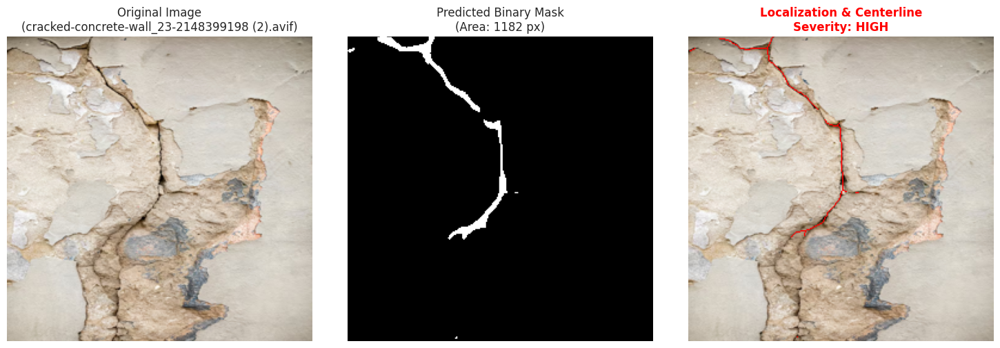

In [86]:
# -------------------------------------------------------------
# CELL 8: Upload and Test Any Concrete Image via Safeguarded Pipeline
# -------------------------------------------------------------
print('Upload one or more images from your local computer to analyze:')
uploaded_files = files.upload()

for fname in uploaded_files.keys():
    analyze_concrete_image_safeguarded(fname)

Upload one or more images from your local computer to analyze:


Saving original.jpg to original.jpg

           CONCRETE CRACK ANALYZER           
Target Surface File  : original.jpg
Detection Status     : CRACKED
Detection Confidence : 99.98%
Crack Area           : 2095.0 pixels
Crack Length         : 508.87 pixels
Average Width        : 4.42 pixels
Maximum Width        : 8.49 pixels
Estimated Severity   : HIGH
--------------------------------------------------
Note: Preliminary inspection assistance only.
Does not replace professional structural assessment.



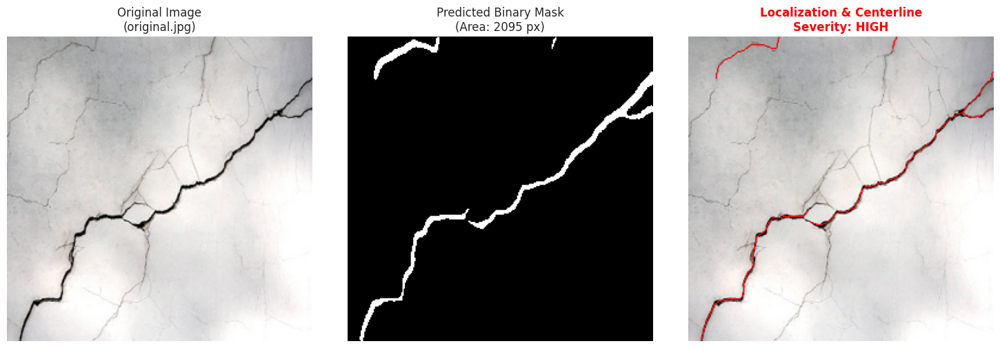

In [87]:
# -------------------------------------------------------------
# CELL 8: Upload and Test Any Concrete Image via Safeguarded Pipeline
# -------------------------------------------------------------
print('Upload one or more images from your local computer to analyze:')
uploaded_files = files.upload()

for fname in uploaded_files.keys():
    analyze_concrete_image_safeguarded(fname)

Upload one or more images from your local computer to analyze:


Saving DSC08006.jpg to DSC08006.jpg

           CONCRETE CRACK ANALYZER           
Target Surface File  : DSC08006.jpg
Detection Status     : CRACKED (OVERRIDDEN BY SEGMENTATION)
Detection Confidence : 100.00%
Crack Area           : 82.0 pixels
Crack Length         : 43.90 pixels
Average Width        : 2.06 pixels
Maximum Width        : 2.83 pixels
Estimated Severity   : LOW
--------------------------------------------------
Note: Preliminary inspection assistance only.
Does not replace professional structural assessment.



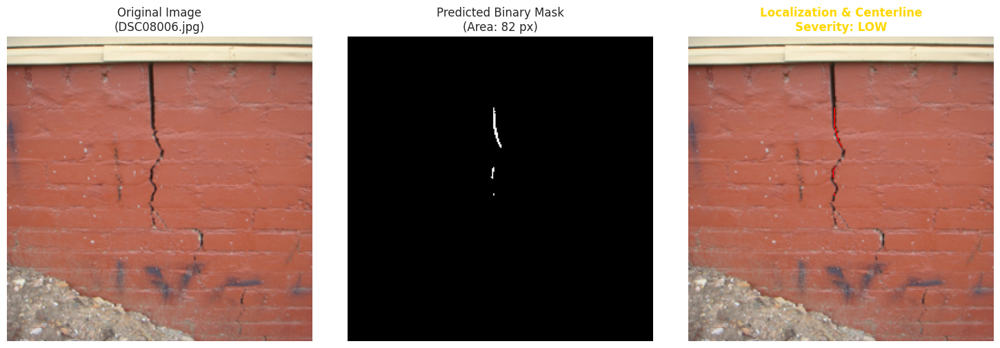

In [89]:
# -------------------------------------------------------------
# CELL 8: Upload and Test Any Concrete Image via Safeguarded Pipeline
# -------------------------------------------------------------
print('Upload one or more images from your local computer to analyze:')
uploaded_files = files.upload()

for fname in uploaded_files.keys():
    analyze_concrete_image_safeguarded(fname)